# Predicting Cognitive Decline from Longitudinal MRI and Patient Data: Full Pipeline
**DSCI 4350 · Group 5**: Christina Dames · Cinthia Ochoa Torre · Rayna Alexandre-Petrie

This notebook runs the whole project end to end, in CRISP-DM order, from the raw OASIS-2 files to the final evaluation on held-out patients. Every step calls the same code in `src/` that the command-line scripts use, so the results here match the files in `reports/`.

| Part | CRISP-DM phase | What happens | Code |
|---|---|---|---|
| 1 | Business & data understanding | Checkpoint 1 notebook: data quality, target definition, first EDA | this notebook |
| 2 | Data preparation | Raw MRI archives → MRI tables; clinical CSV → ML-ready visit pairs; EDA report | `src/data/`, `src/visualization/` |
| 3 | Data preparation | 64³ MRI volumes for the CNNs | `src/data/make_mri_volumes.py` |
| 4 | Modeling | Baselines: Model 2 (metadata-only) and tabular MRI measures | `src/models/evaluate.py` |
| 5 | Modeling | Model 1 (3D CNN, MRI-only) and Model 3 (3D CNN + metadata) | `src/models/cnn.py`, `train_cnn.py` |
| 6 | Modeling | Hyperparameter optimization with Optuna | `src/models/tune.py` |
| 7 | Evaluation | Cross-validated comparison of every model | `src/visualization/model_comparison.py` |
| 8 | Evaluation / deployment | Monitoring: data quality, drift, calibration, subgroups | `src/monitoring/drift.py` |
| 9 | Evaluation | **Final, one-time evaluation on the held-out test patients** | `src/models/final_evaluation.py` |
| 10 | Conclusions | Answers to the project question | |

**Validation protocol (used throughout):** patients are split once into training (119 patients, 178 visit pairs) and test (31 patients, 45 pairs). All model development, tuning and model selection use **patient-grouped 5-fold cross-validation inside the training patients**. The test patients are used only once, in Part 9.

**Requirements:** `pip install -r requirements.txt`; the two OASIS-2 archives `OAS2_RAW_PART1.tar.gz` and `OAS2_RAW_PART2.tar.gz` in `data/raw/` (about 19 GB, read as a stream, not extracted). Full run time is about 45 minutes on an Apple M2 laptop CPU.

## 0. Setup

In [1]:
import os, sys, json, time, platform, warnings
from pathlib import Path

# Run from the project root so the src/ package and relative paths resolve
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

# Import the project modules first: the report modules select a non-interactive
# matplotlib backend on import, and %matplotlib inline below switches it back.
from src import config
from src.data import make_mri_dataset, make_dataset, make_mri_volumes
from src.visualization import eda_report, model_comparison
from src.models import evaluate, cnn, train_cnn, tune, final_evaluation
from src.monitoring import drift

import numpy as np, pandas as pd, sklearn, torch, optuna
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display

PIPELINE_START = time.perf_counter()
print("Project root:", ROOT)
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | torch {torch.__version__} | optuna {optuna.__version__}")
print("Machine:", platform.platform(), "|", os.cpu_count(), "CPU cores")
print("MRI archives present:", [p.name for p in config.MRI_ARCHIVES if p.exists()])

/Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression
Python 3.14.2 | numpy 2.5.5 | pandas 3.1.1 | scikit-learn 1.9.1 | torch 2.15.0 | optuna 5.1.0
Machine: macOS-27.2-arm64-arm-64bit-Mach-O | 8 CPU cores
MRI archives present: ['OAS2_RAW_PART1.tar.gz', 'OAS2_RAW_PART2.tar.gz']


In [2]:
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)
pd.set_option("display.width", 160, "display.max_columns", 40)

def show_figure(name, width=900):
    """Display one of the saved report figures."""
    display(Image(filename=str(config.FIGURES_DIR / name), width=width))

---
# Part 1: Business & Data Understanding (Checkpoint 1)
The cells below are the Checkpoint 1 notebook (`CheckPoint_1/dsci-4350-project.ipynb`), re-run unchanged. It works directly on the raw Kaggle copy of the OASIS-2 clinical CSV.

## Predicting Alzheimer's Disease Progression — Business & Data Understanding
**DSCI 4350 · Group 5 · First Checkpoint (Part 3)**
Christina Dames · Cinthia Ochoa Torre · Rayna Alexandre-Petrie

**Goal of this notebook:** explore the OASIS-2 longitudinal dataset, assess data quality, build the prediction target (*stable vs. declined at the next visit*), and document initial findings that guide data preparation and modeling in the next sprints (CRISP-DM: Business Understanding → Data Understanding).

## 1. Business Understanding → Data Science Goals

| Business objective | Data science goal |
|---|---|
| Know whether a patient's cognitive status will get worse | Binary classification: **stable (0) vs. declined (1)** at the next visit, using information from the earlier visit |
| Know which information is most useful | Compare 3 models (**MRI-only, metadata-only, combined**) using F1-score and ROC-AUC |
| Make predictions that work for new patients | **Patient-level** train/test split (no patient appears in both sets) |

**Decline definition:** the Clinical Dementia Rating (CDR) increases from one visit to the next (e.g., 0 → 0.5).

## 2. Data Acquisition

| Source | Content | Use |
|---|---|---|
| OASIS-2 longitudinal CSV (Kaggle: *MRI and Alzheimers*) | Demographics, cognitive scores, MRI-derived brain measures per visit | EDA + metadata model (this checkpoint) |
| OASIS-2 Longitudinal Scan Data (oasis-brains.org, ~18 GB raw 3D MRI) | Brain scans for the same patients and visits (matched by MRI ID) | CNN / MRI model (Sprint 2) |

In [3]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4.5)


df = pd.read_csv('oasis_longitudinal.csv')

print("Shape:", df.shape)
df.head()

Shape: (373, 15)


,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034


### Column dictionary
Each **row is one visit** of one patient.

| Column | Meaning |
|---|---|
| Subject ID / MRI ID | Patient ID / ID of that visit's scan |
| Group | Nondemented, Demented, Converted (became demented during the study) |
| Visit, MR Delay | Visit number; days since the first visit |
| M/F, Hand, Age | Sex, dominant hand, age at visit |
| EDUC, SES | Years of education; socioeconomic status (1 = highest, 5 = lowest) |
| MMSE | Mini-Mental State Exam, 0–30 (lower = worse) |
| CDR | Clinical Dementia Rating: 0 normal, 0.5 very mild, 1 mild, 2 moderate |
| eTIV, nWBV, ASF | Intracranial volume; normalized whole-brain volume (drops with atrophy); atlas scaling factor |

## 3. Data Quality Report

### 3.1 Patients and visits

In [4]:
print("Patients:", df['Subject ID'].nunique())
print("Visits:", len(df))
print("\nNumber of patients by number of visits:")
print(df['Subject ID'].value_counts().value_counts().sort_index())

Patients: 150
Visits: 373

Number of patients by number of visits:
count
2    94
3    43
4     9
5     4
Name: count, dtype: int64


**Observation:** 150 patients, 373 visits. Every patient has **at least 2 visits** (94 have exactly 2), so all patients can be used for visit-to-next-visit prediction.

### 3.2 Missing values

In [5]:
missing = df.isnull().sum()
pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(1)})

,missing,percent
Subject ID,0,0.0
MRI ID,0,0.0
Group,0,0.0
Visit,0,0.0
MR Delay,0,0.0
M/F,0,0.0
Hand,0,0.0
Age,0,0.0
EDUC,0,0.0
SES,19,5.1


**Observation:** only **SES (19 missing, 5.1%)** and **MMSE (2 missing, 0.5%)** have missing values; all other columns are complete.

### 3.3 Summary statistics

In [6]:
df.describe().round(2)

,Visit,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,373.00,373.00,373.00,373.00,354.00,371.00,373.00,373.00,373.00,373.00
mean,1.88,595.10,77.01,14.60,2.46,27.34,0.29,1488.13,0.73,1.20
std,0.92,635.49,7.64,2.88,1.13,3.68,0.37,176.14,0.04,0.14
min,1.00,0.00,60.00,6.00,1.00,4.00,0.00,1106.00,0.64,0.88
25%,1.00,0.00,71.00,12.00,2.00,27.00,0.00,1357.00,0.70,1.10
50%,2.00,552.00,77.00,15.00,2.00,29.00,0.00,1470.00,0.73,1.19
75%,2.00,873.00,82.00,16.00,3.00,30.00,0.50,1597.00,0.76,1.29
max,5.00,2639.00,98.00,23.00,5.00,30.00,2.00,2004.00,0.84,1.59


In [7]:
print(df['Group'].value_counts(), "\n")
print(df['Hand'].value_counts(), "\n")
print(df['CDR'].value_counts().sort_index())

Group
Nondemented    190
Demented       146
Converted       37
Name: count, dtype: int64 

Hand
R    373
Name: count, dtype: int64 

CDR
0.0    206
0.5    123
1.0     41
2.0      3
Name: count, dtype: int64


**Observations**
- Age ranges from 60 to 98 (mean 77).
- MMSE minimum is **4** (typical range 27–30): a real severe case, kept as an outlier.
- **Hand** is constant (all right-handed) → no information.
- Only **3 visits have CDR = 2** → too few to draw conclusions for that level.
- **Group** is assigned using the patient's *whole* history, including future visits → using it as a feature would cause **data leakage**.
- MR Delay ranges from 0 to 2,639 days (~7 years) of follow-up.

### 3.4 Data preparation steps (Sprint 2)

| Issue | Action |
|---|---|
| SES: 19 missing | Fill with mode |
| MMSE: 2 missing | Fill with median |
| Hand: constant | Drop column |
| Group: uses future information | Exclude from features (leakage) |
| Time between visits varies | Add `days_to_next` feature |
| Visits of same patient are related | Patient-level train/test split |

## 4. Target Variable: Stable vs. Declined
For each visit, we look at the CDR of the **next** visit. If it increases, the pair is labeled **declined (1)**; otherwise **stable (0)**. The last visit of each patient has no next visit and is removed.

In [8]:
df = df.sort_values(['Subject ID', 'Visit'])

# CDR and days until the next visit of the same patient
df['CDR_next'] = df.groupby('Subject ID')['CDR'].shift(-1)
df['days_to_next'] = df.groupby('Subject ID')['MR Delay'].shift(-1) - df['MR Delay']

# Keep only visits that have a next visit
pairs = df.dropna(subset=['CDR_next']).copy()
pairs['declined'] = (pairs['CDR_next'] > pairs['CDR']).astype(int)

print("Number of visit pairs:", len(pairs))
print(pairs['declined'].value_counts())
print("Decline rate:", round(pairs['declined'].mean() * 100, 1), "%")

Number of visit pairs: 223
declined
0    192
1     31
Name: count, dtype: int64
Decline rate: 13.9 %


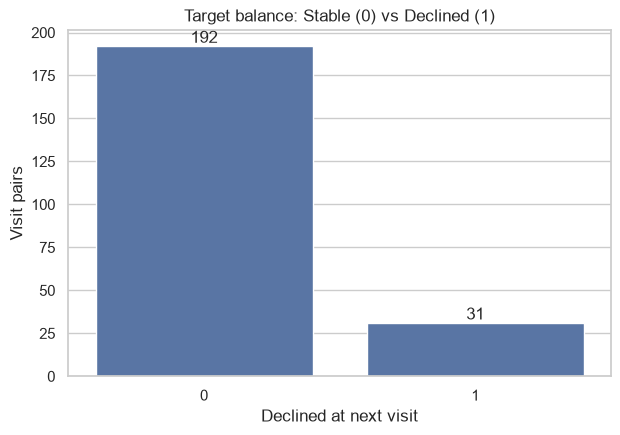

In [9]:
ax = sns.countplot(x='declined', data=pairs)
ax.bar_label(ax.containers[0])
plt.title('Target balance: Stable (0) vs Declined (1)')
plt.xlabel('Declined at next visit')
plt.ylabel('Visit pairs')
plt.show()

**Observation:** 223 visit pairs, only **31 declined (14%)** vs. 192 stable (86%). The target is **imbalanced**: a model that always predicts "stable" would reach 86% accuracy while finding zero decliners. → We will evaluate with **recall, F1-score and ROC-AUC**, not only accuracy.

## 5. Exploratory Data Analysis

### 5.1 Brain volume and dementia severity

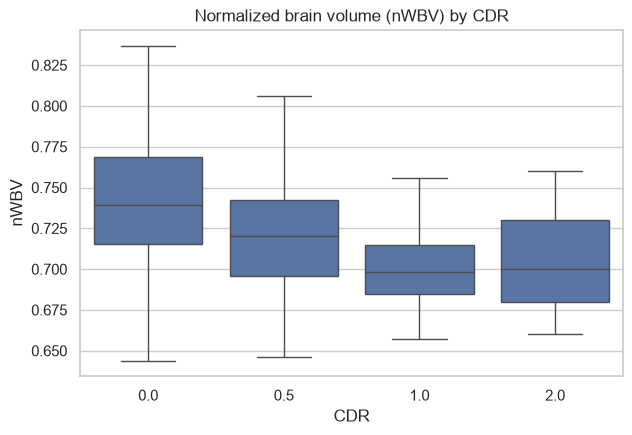

In [10]:
sns.boxplot(x='CDR', y='nWBV', data=df)
plt.title('Normalized brain volume (nWBV) by CDR')
plt.show()

**Observation:** median nWBV decreases as CDR increases (≈0.74 → 0.72 → 0.70): more dementia, more brain atrophy. MRI-derived features carry useful information, but boxes overlap heavily. (CDR 2 has only 3 visits.)

### 5.2 Age vs. brain volume

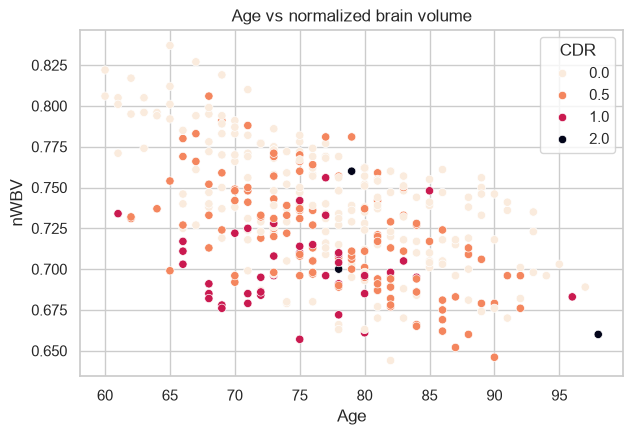

In [11]:
sns.scatterplot(x='Age', y='nWBV', hue='CDR', data=df, palette='rocket_r')
plt.title('Age vs normalized brain volume')
plt.show()

**Observation:** brain volume decreases with **age** even in healthy patients, and at the same age, patients with higher CDR tend to have lower nWBV. → Age must be included so the model does not confuse normal aging with dementia.

### 5.3 Does earlier brain volume predict decline?

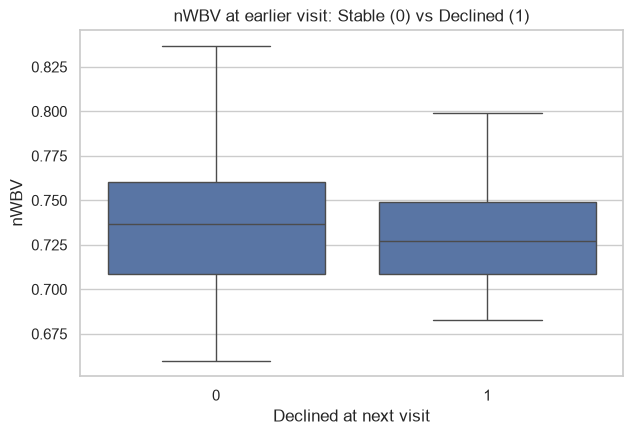

declined
0    0.736
1    0.727
Name: nWBV, dtype: float64


In [12]:
sns.boxplot(x='declined', y='nWBV', data=pairs)
plt.title('nWBV at earlier visit: Stable (0) vs Declined (1)')
plt.xlabel('Declined at next visit')
plt.show()

print(pairs.groupby('declined')['nWBV'].median().round(3))

**Observation:** patients who later declined had slightly lower brain volume (median ≈0.727 vs 0.736), but the distributions **overlap almost completely**. → MRI-derived volume alone is likely a weak predictor; combining it with patient metadata may add value (this is what our multimodal comparison tests).

### 5.4 Patient features: stable vs. declined

In [13]:
features = ['Age', 'EDUC', 'SES', 'MMSE', 'CDR', 'nWBV', 'days_to_next']
pairs.groupby('declined')[features].mean().round(2)

,Age,EDUC,SES,MMSE,CDR,nWBV,days_to_next
declined,,,,,,,
0,75.99,14.63,2.47,27.86,0.24,0.74,708.79
1,76.65,14.71,2.22,26.90,0.31,0.73,780.45


In [14]:
rate = pd.crosstab(pairs['CDR'], pairs['declined'])
rate['decline_rate_%'] = (rate[1] / rate.sum(axis=1) * 100).round(1)
rate

declined,0,1,decline_rate_%
CDR,,,
0.0,118,15,11.3
0.5,57,13,18.6
1.0,17,3,15.0


**Observations**
- **MMSE** is lower in patients who later declined (≈26.9 vs 27.9).
- Patients starting at **CDR 0.5 decline more often (≈19%)** than those at CDR 0 (≈11%) — very mild symptoms often precede further decline.
- Age and education are very similar between groups.

### 5.5 Time between visits

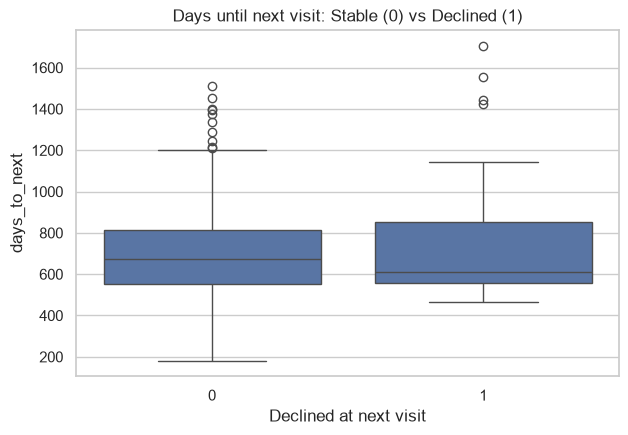

           mean  median    min
declined                      
0         709.0   674.0  182.0
1         780.0   610.0  465.0


In [15]:
sns.boxplot(x='declined', y='days_to_next', data=pairs)
plt.title('Days until next visit: Stable (0) vs Declined (1)')
plt.xlabel('Declined at next visit')
plt.show()

print(pairs.groupby('declined')['days_to_next'].agg(['mean', 'median', 'min']).round(0))

**Observation:** mean gap is slightly higher for decliners (780 vs 709 days), but the median is lower, and the difference is driven by a few outliers (>1,400 days). Time between visits does not separate the groups well, but it is kept as a feature because patients were followed for different lengths of time.

## 6. Initial Findings

1. **Small longitudinal dataset:** 150 patients, 373 visits → only **223 visit pairs** for modeling.
2. **Imbalanced target:** 31 declined (14%) vs 192 stable → use F1, recall and ROC-AUC with a patient-level split.
3. **Brain volume drops with dementia and age,** but at the earlier visit decliners are only slightly lower → MRI alone is likely weak; combining sources may help.
4. **MMSE and starting CDR are the most informative features:** lower MMSE and CDR 0.5 are associated with later decline.
5. **Data source issue resolved:** the reference Kaggle notebooks use OASIS-1 (one scan per person, no follow-up). We located the **OASIS-2 longitudinal scans**, which match our CSV visits by MRI ID, so the MRI-only and combined models are feasible.

## 7. Next Steps (Sprint 2)
- Apply the data preparation steps from Section 3.4.
- Download the OASIS-2 scans and set up MRI preprocessing for the CNN.
- Build the patient-level train/test split and baseline metadata-only model.

---
# Part 2: Data Preparation
Checkpoint 1 listed the preparation steps (impute SES/MMSE, drop `Hand` and `Group`, add `days_to_next`, patient-level split). They are implemented as scripts in `src/data/` so the dataset can be rebuilt exactly.

## 2.1 MRI tables from the raw OASIS-2 archives
`make_mri_dataset` streams both archives in parallel (no extraction), reads every raw T1 scan (1,367 scans in 373 sessions), and computes per-scan header metadata, intensity statistics, signal-to-noise ratio and a CSF-fraction proxy, plus repeat-scan agreement and a quality-control flag per session.

In [16]:
t0 = time.perf_counter()
make_mri_dataset.main()
print(f"\nRuntime: {(time.perf_counter() - t0) / 60:.1f} min")

Wrote 1367 scans / 373 sessions to /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/data/processed
{
  "clinical_visits": 373,
  "mri_sessions": 373,
  "visits_with_scan": 373,
  "visit_pairs": 223,
  "pairs_with_scan_at_t": 223,
  "pairs_with_scans_at_both_visits": 223
}

Runtime: 3.0 min


In [17]:
sessions = pd.read_csv(config.MRI_SESSIONS_CSV)
mri_meta = json.loads(config.MRI_METADATA.read_text())
print("Sessions:", len(sessions), "| scans:", mri_meta["scans"], "| subjects:", mri_meta["subjects"])
print("QC-flagged sessions (low SNR or head motion):", len(mri_meta["qc_flagged_sessions"]))
print("Linkage to clinical visits:", {k: v for k, v in mri_meta["linkage"].items() if not isinstance(v, list)})
sessions.head()

Sessions: 373 | scans: 1367 | subjects: 150
QC-flagged sessions (low SNR or head motion): 19
Linkage to clinical visits: {'clinical_visits': 373, 'mri_sessions': 373, 'visits_with_scan': 373, 'visit_pairs': 223, 'pairs_with_scan_at_t': 223, 'pairs_with_scans_at_both_visits': 223}


,mri_id,archive,n_scans,snr,foreground_p50,foreground_p99,foreground_volume_cm3,csf_fraction_proxy,repeat_scan_r,subject_id,session,low_snr,low_repeat_scan_r,qc_flag
0,OAS2_0001_MR1,OAS2_RAW_PART1.tar.gz,3,18.336618,1131.000000,2713.333333,2362.113333,0.251937,0.991310,OAS2_0001,1,0,0,0
1,OAS2_0001_MR2,OAS2_RAW_PART1.tar.gz,3,16.723786,1186.666667,2676.333333,2184.128750,0.260443,0.969436,OAS2_0001,2,0,0,0
2,OAS2_0002_MR1,OAS2_RAW_PART1.tar.gz,4,21.335223,885.000000,1995.500000,2374.713125,0.272292,0.967005,OAS2_0002,1,0,0,0
3,OAS2_0002_MR2,OAS2_RAW_PART1.tar.gz,4,22.287610,1283.500000,3172.750000,2001.791875,0.354874,0.980415,OAS2_0002,2,0,0,0
4,OAS2_0002_MR3,OAS2_RAW_PART1.tar.gz,3,20.999150,1366.666667,3256.000000,2071.778750,0.333000,0.992000,OAS2_0002,3,0,0,0


## 2.2 ML-ready visit pairs
`make_dataset` turns the 373 visits into 223 (visit *t*, next visit) pairs. The target `declined` = 1 when the CDR at the next visit is higher than at visit *t*. Everything else is known at visit *t*:
- MMSE missing values are filled from the patient's previous visit; SES is imputed with **training-patient statistics only**.
- Backward-looking change features (MMSE, nWBV and CDR change since the previous visit, and their rates).
- The MRI CSF proxy of visit *t* from Part 2.1.
- `Group` is dropped (it uses the patient's future, so it would leak the target) and `Hand` is dropped (constant).
- **Patient-level split** with `StratifiedGroupKFold` (seed 42): 1 of 5 patient groups becomes the test set; the training patients get 5 grouped CV folds.

In [18]:
make_dataset.main()

Wrote 223 visit pairs to /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/data/processed/oasis2_visit_pairs.csv
{
  "test": {
    "patients": 31,
    "visit_pairs": 45,
    "declined": 6,
    "decline_rate": 0.1333
  },
  "train": {
    "patients": 119,
    "visit_pairs": 178,
    "declined": 25,
    "decline_rate": 0.1404
  }
}


In [19]:
pairs = pd.read_csv(config.ML_READY_CSV)
meta = json.loads(config.ML_READY_METADATA.read_text())
display(pd.DataFrame(meta["lineage"]))
summary = (pairs.groupby("split")
           .agg(patients=("subject_id", "nunique"), visit_pairs=("declined", "size"),
                declined=("declined", "sum"), decline_rate=("declined", "mean")).round(3))
display(summary)
print("Training pairs per CV fold:", pairs.query("split == 'train'")["cv_fold"].value_counts().sort_index().to_dict())
print("Patients in both train and test:",
      len(set(pairs.query("split=='train'").subject_id) & set(pairs.query("split=='test'").subject_id)))
print(f"\n{len(config.FEATURE_COLUMNS)} features:", config.FEATURE_COLUMNS)

,step,rows,patients
0,Load raw OASIS-2 CSV,373,150
1,Fill MMSE from previous visit; add change feat...,373,150
2,Pair each visit with the next; drop last visits,223,150
3,Attach MRI session measures of visit t (mri_id),223,150
4,Split by patient; impute SES; encode; select c...,223,150


,patients,visit_pairs,declined,decline_rate
split,,,,
test,31,45,6,0.133
train,119,178,25,0.140


Training pairs per CV fold: {0: 36, 1: 36, 2: 35, 3: 35, 4: 36}
Patients in both train and test: 0

20 features: ['age', 'sex_male', 'educ', 'ses', 'ses_imputed', 'mmse', 'cdr', 'etiv', 'nwbv', 'asf', 'days_since_baseline', 'days_to_next', 'has_prev_visit', 'days_since_prev', 'mmse_change_prev', 'nwbv_change_prev', 'cdr_change_prev', 'mmse_rate_prev', 'nwbv_rate_prev', 'mri_csf_proxy']


Reproducibility check: the rebuilt tables are compared with the versions committed to git (only timestamps in the metadata JSON files should differ).

In [20]:
import subprocess
print(subprocess.run(["git", "diff", "--stat", "--", "data/processed"],
                     capture_output=True, text=True).stdout or "No differences from the committed data.")

 data/processed/oasis2_mri_metadata.json         |   4 +-
 data/processed/oasis2_mri_sessions.csv          | 258 ++++++++---------
 data/processed/oasis2_visit_pairs.csv           | 352 ++++++++++++------------
 data/processed/oasis2_visit_pairs_metadata.json |   6 +-
 4 files changed, 310 insertions(+), 310 deletions(-)



**Result:** the rebuilt `data/processed` files differ from the committed ones only in timestamps, file hashes, and floating-point noise (largest difference 4.6 × 10⁻¹³, in `foreground_volume_cm3`). Targets, features, the train/test split and the CV folds are identical, so the pipeline is reproducible from the raw files.

## 2.3 EDA report (Checkpoint 2)
`eda_report` rebuilds the full EDA report on the ML-ready data (`reports/eda_report.pdf`, figures in `reports/figures/`). A few key pages:

In [21]:
eda_report.main()

Wrote /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/reports/eda_report.pdf (21 pages)
            feature   auc  strength         direction
               mmse 0.389     0.611  lower -> decline
days_since_baseline 0.390     0.610  lower -> decline
    days_since_prev 0.395     0.605  lower -> decline
     has_prev_visit 0.400     0.600  lower -> decline
     nwbv_rate_prev 0.596     0.596 higher -> decline
   nwbv_change_prev 0.595     0.595 higher -> decline
                cdr 0.560     0.560 higher -> decline
                ses 0.451     0.549  lower -> decline
               nwbv 0.463     0.537  lower -> decline
            mri_snr 0.464     0.536  lower -> decline
        ses_imputed 0.533     0.533 higher -> decline
           sex_male 0.521     0.521 higher -> decline
      mri_csf_proxy 0.480     0.520  lower -> decline
                age 0.518     0.518 higher -> decline
                asf 0.487     0.513  lower -> decline
     

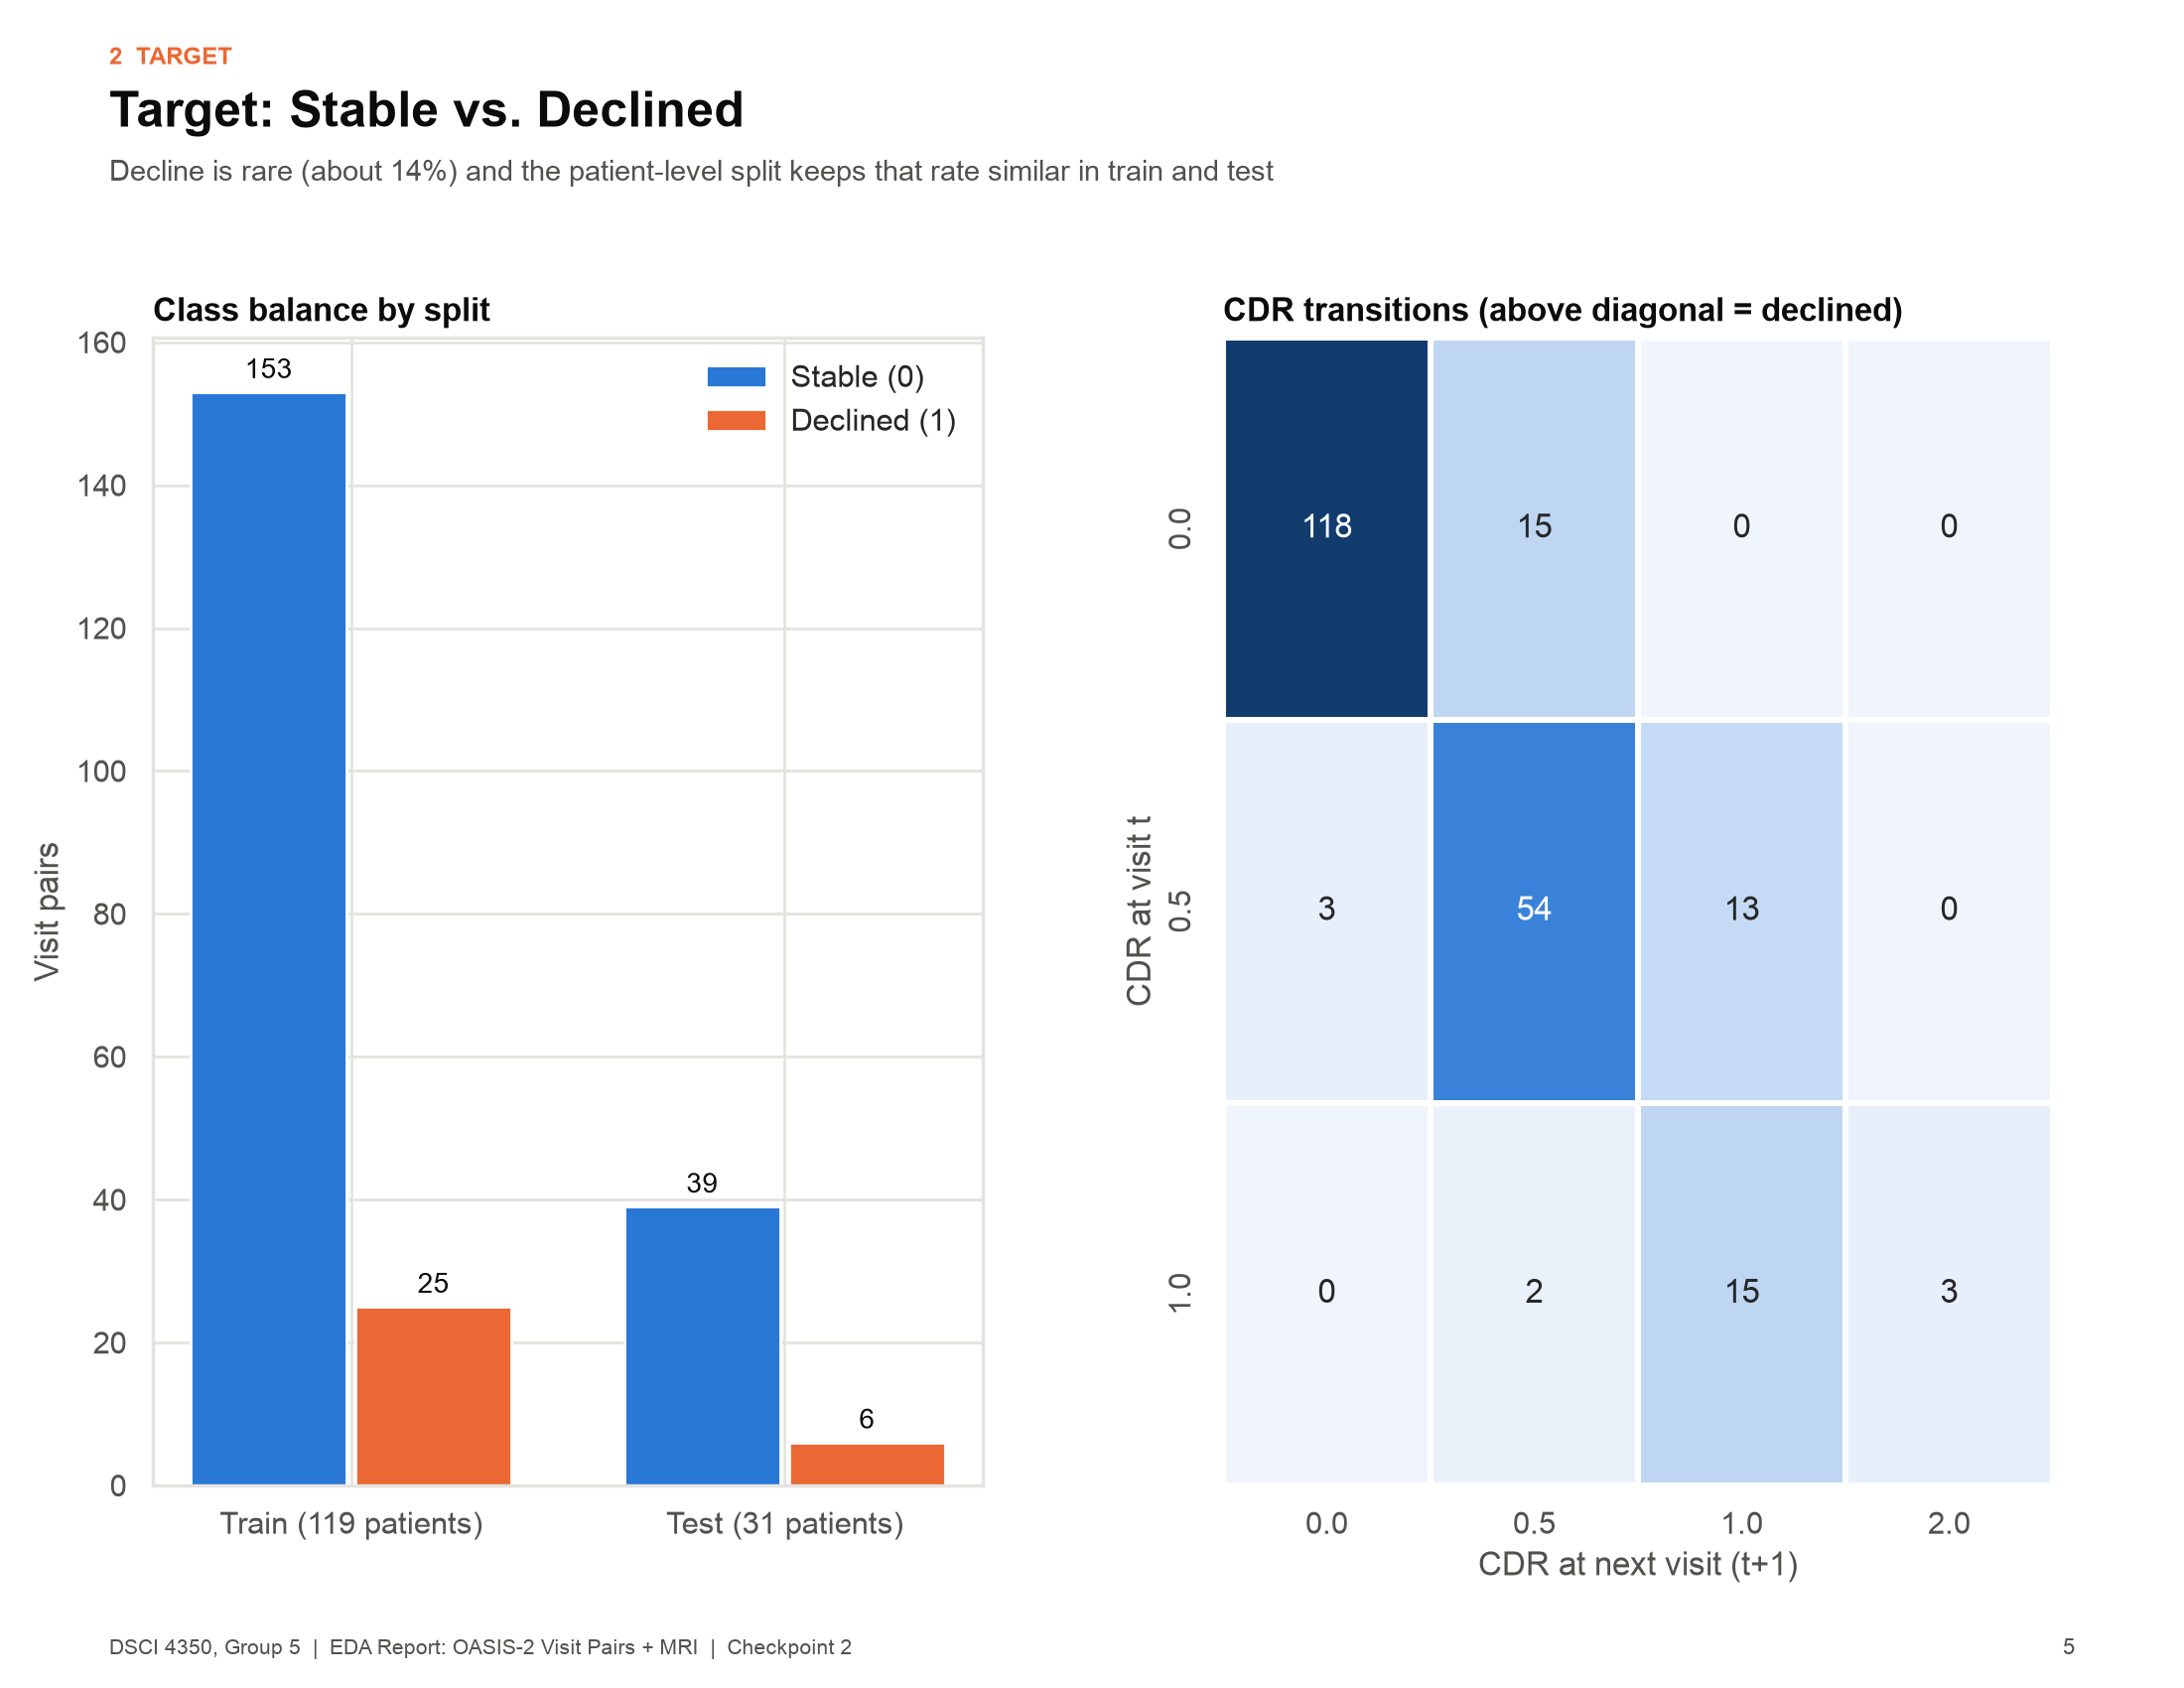

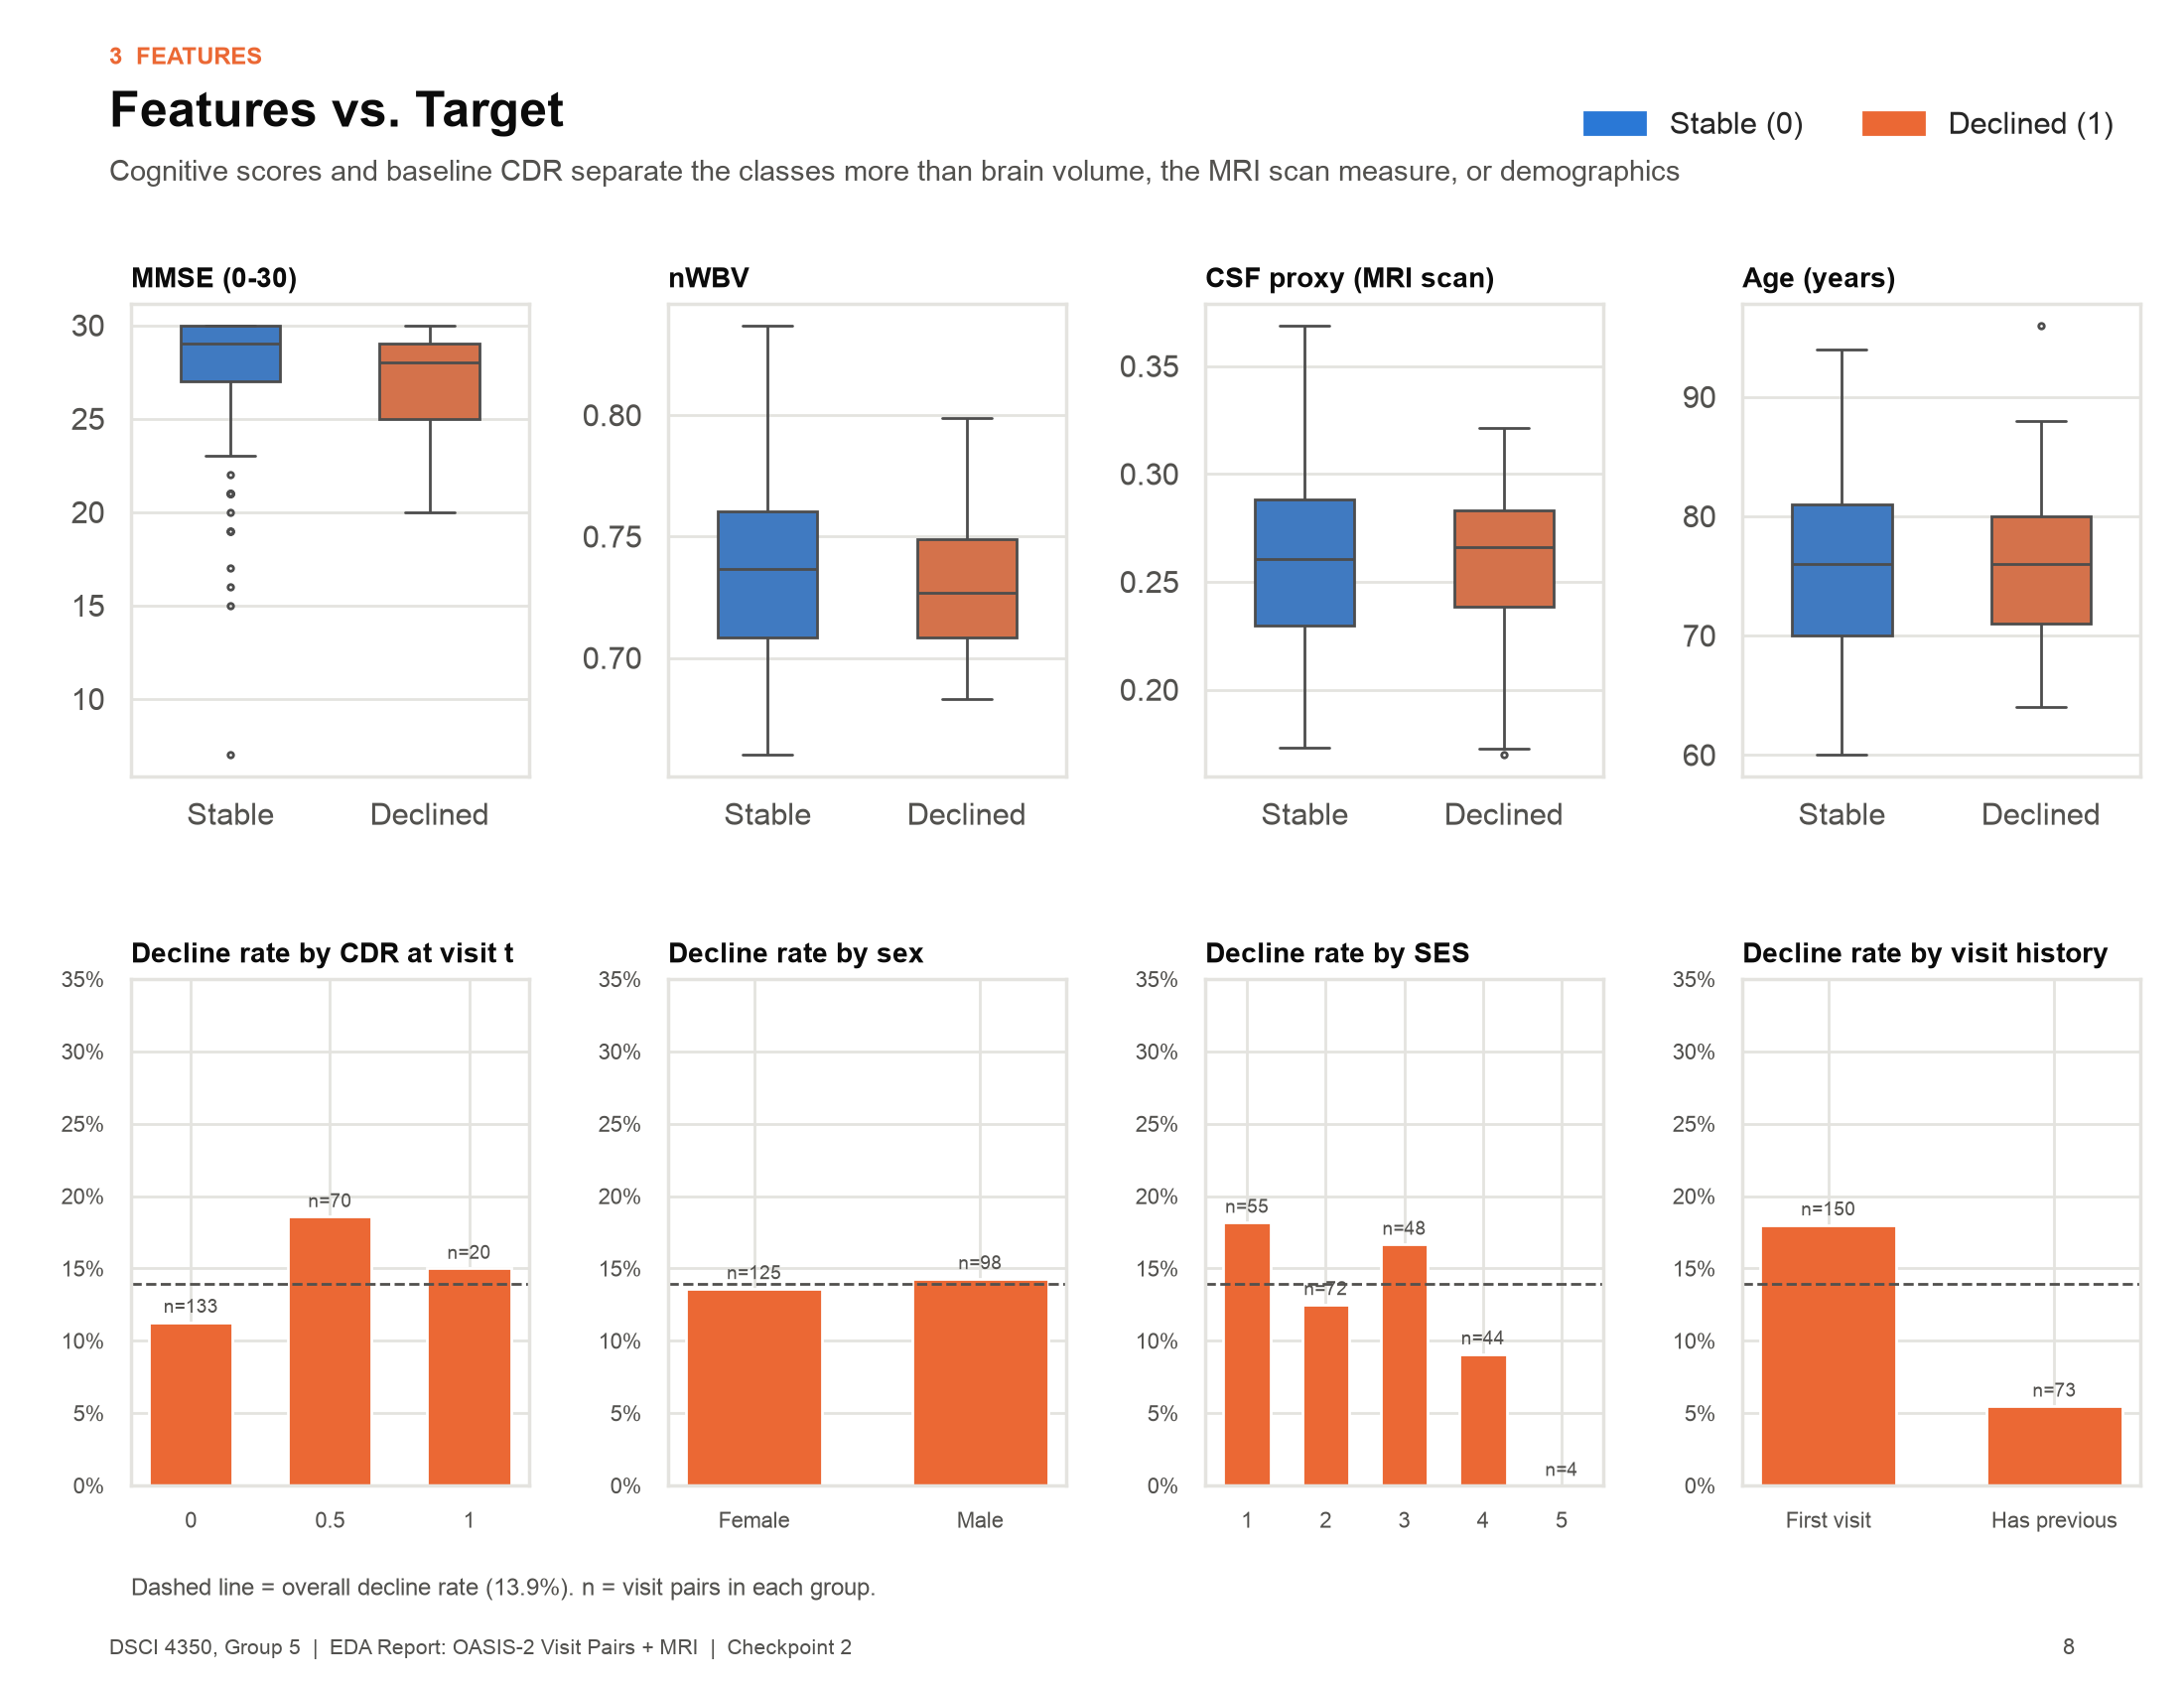

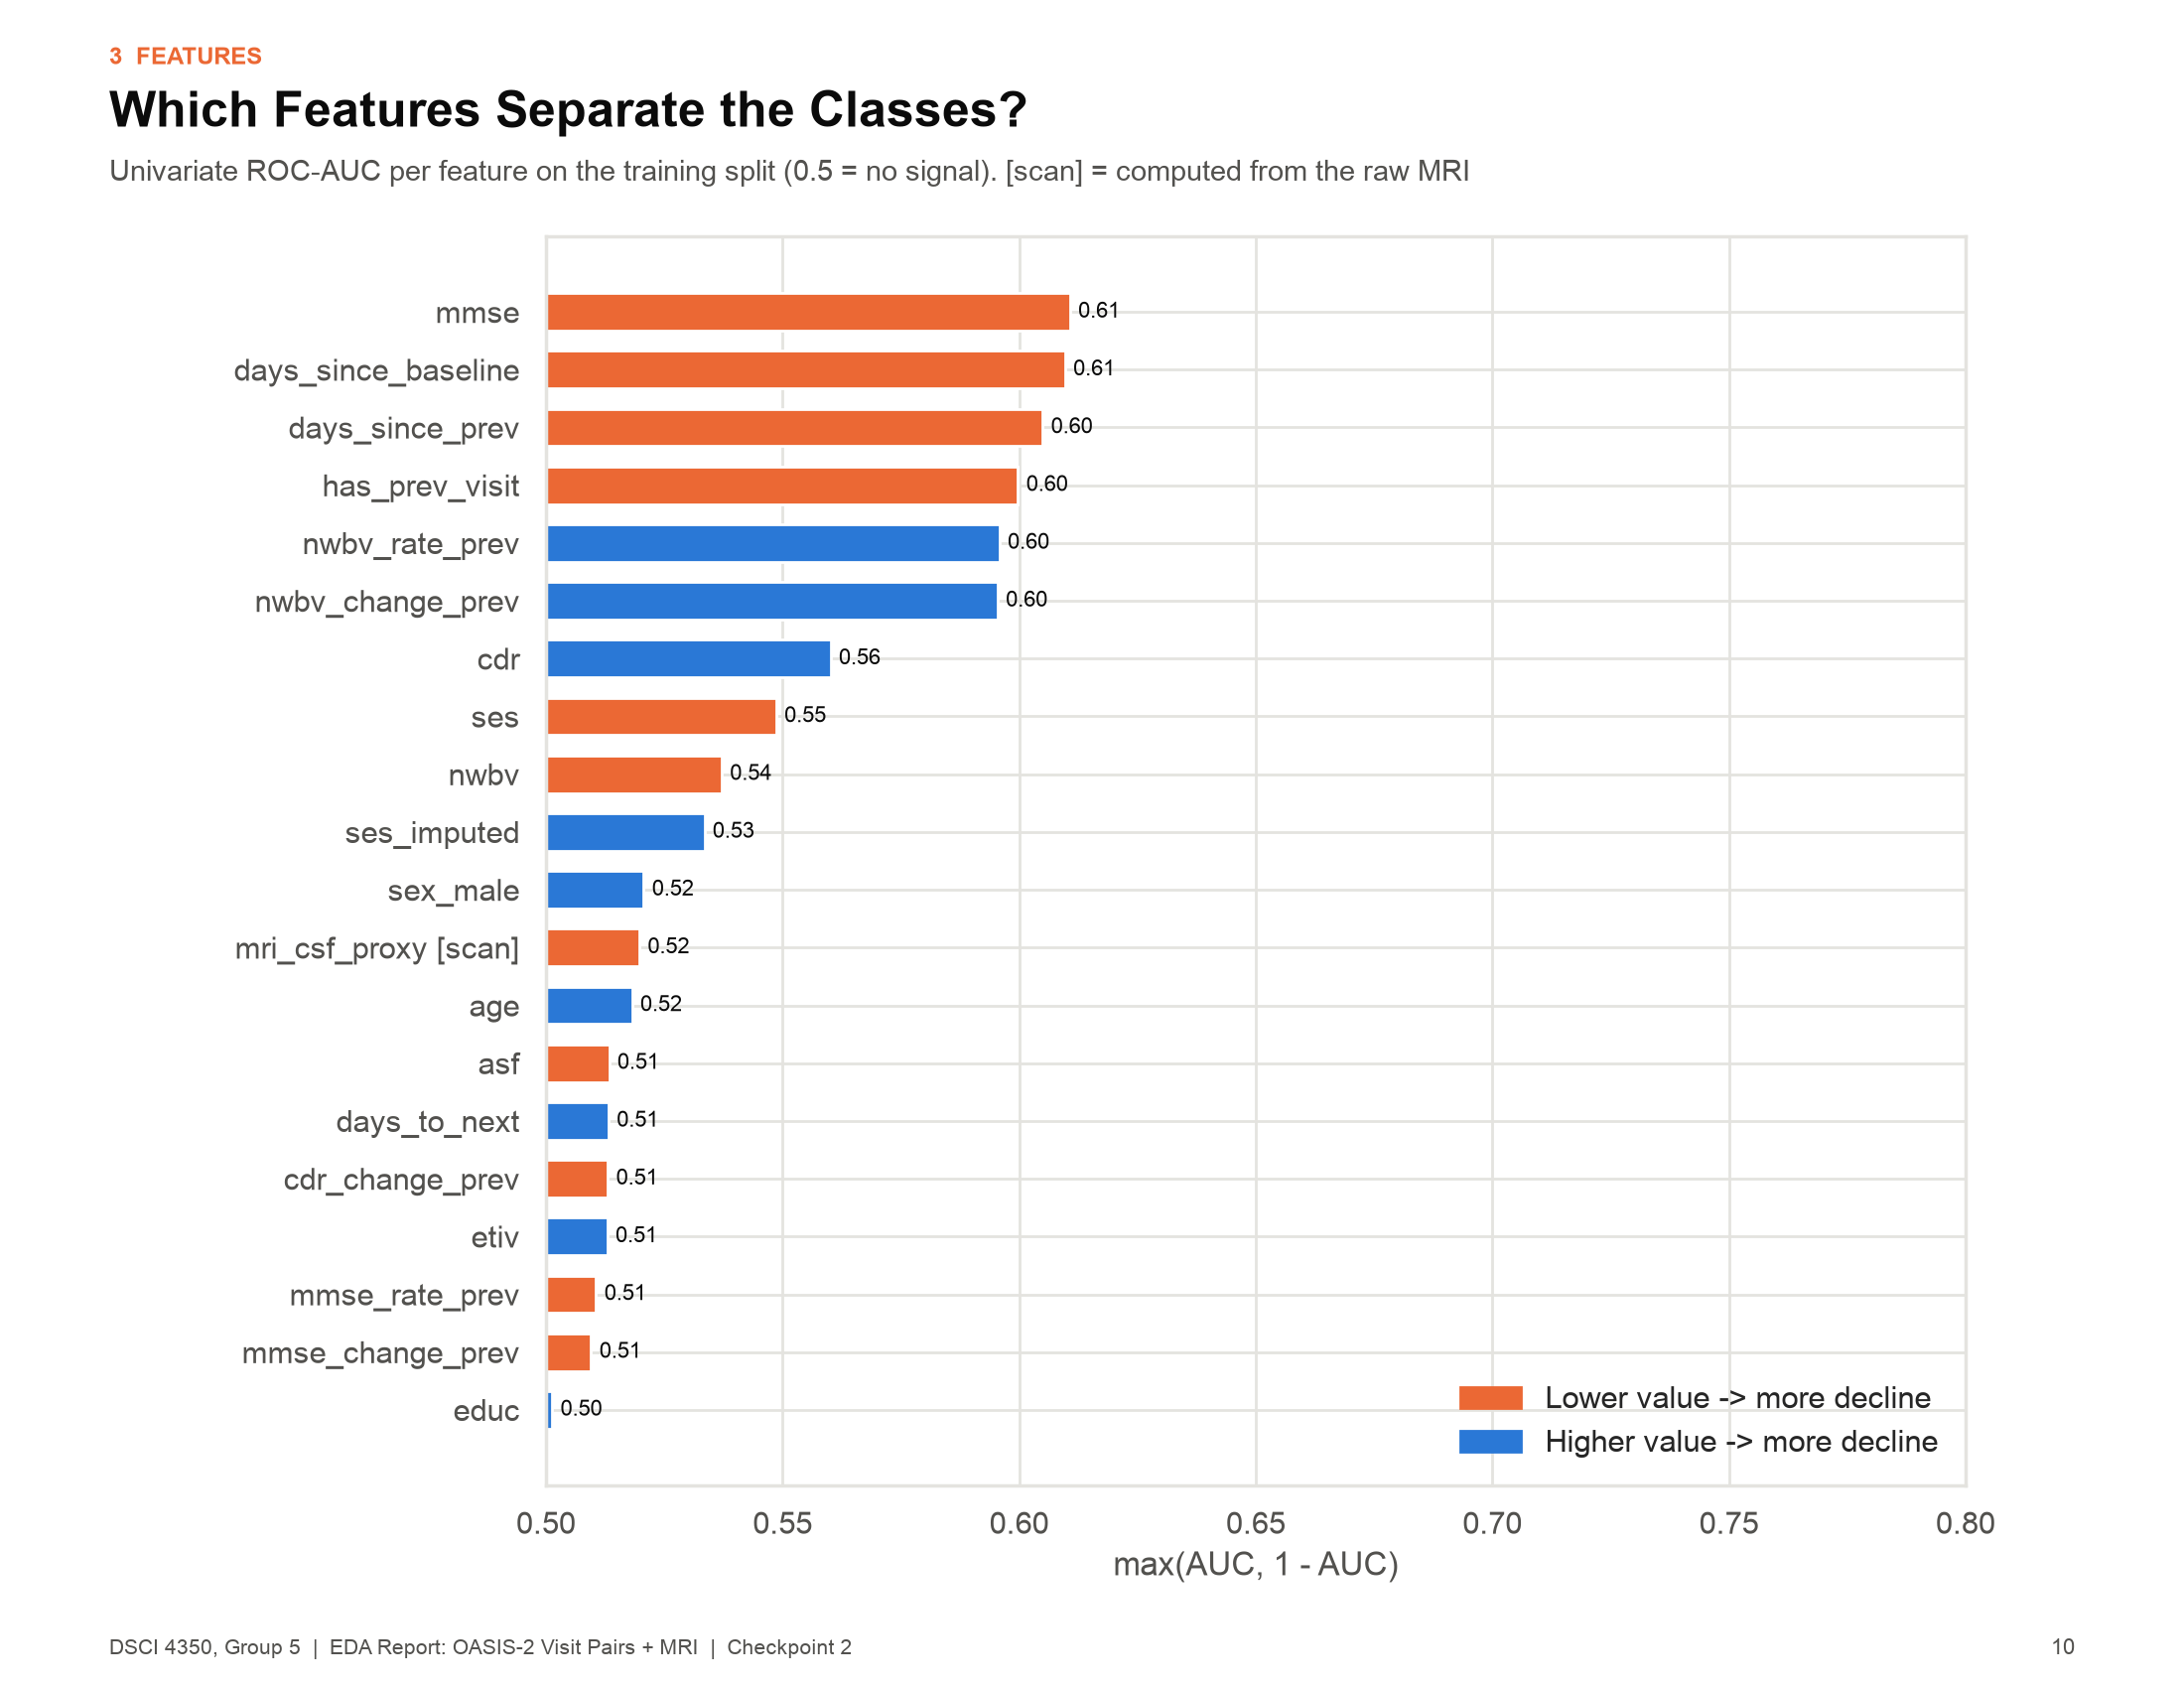

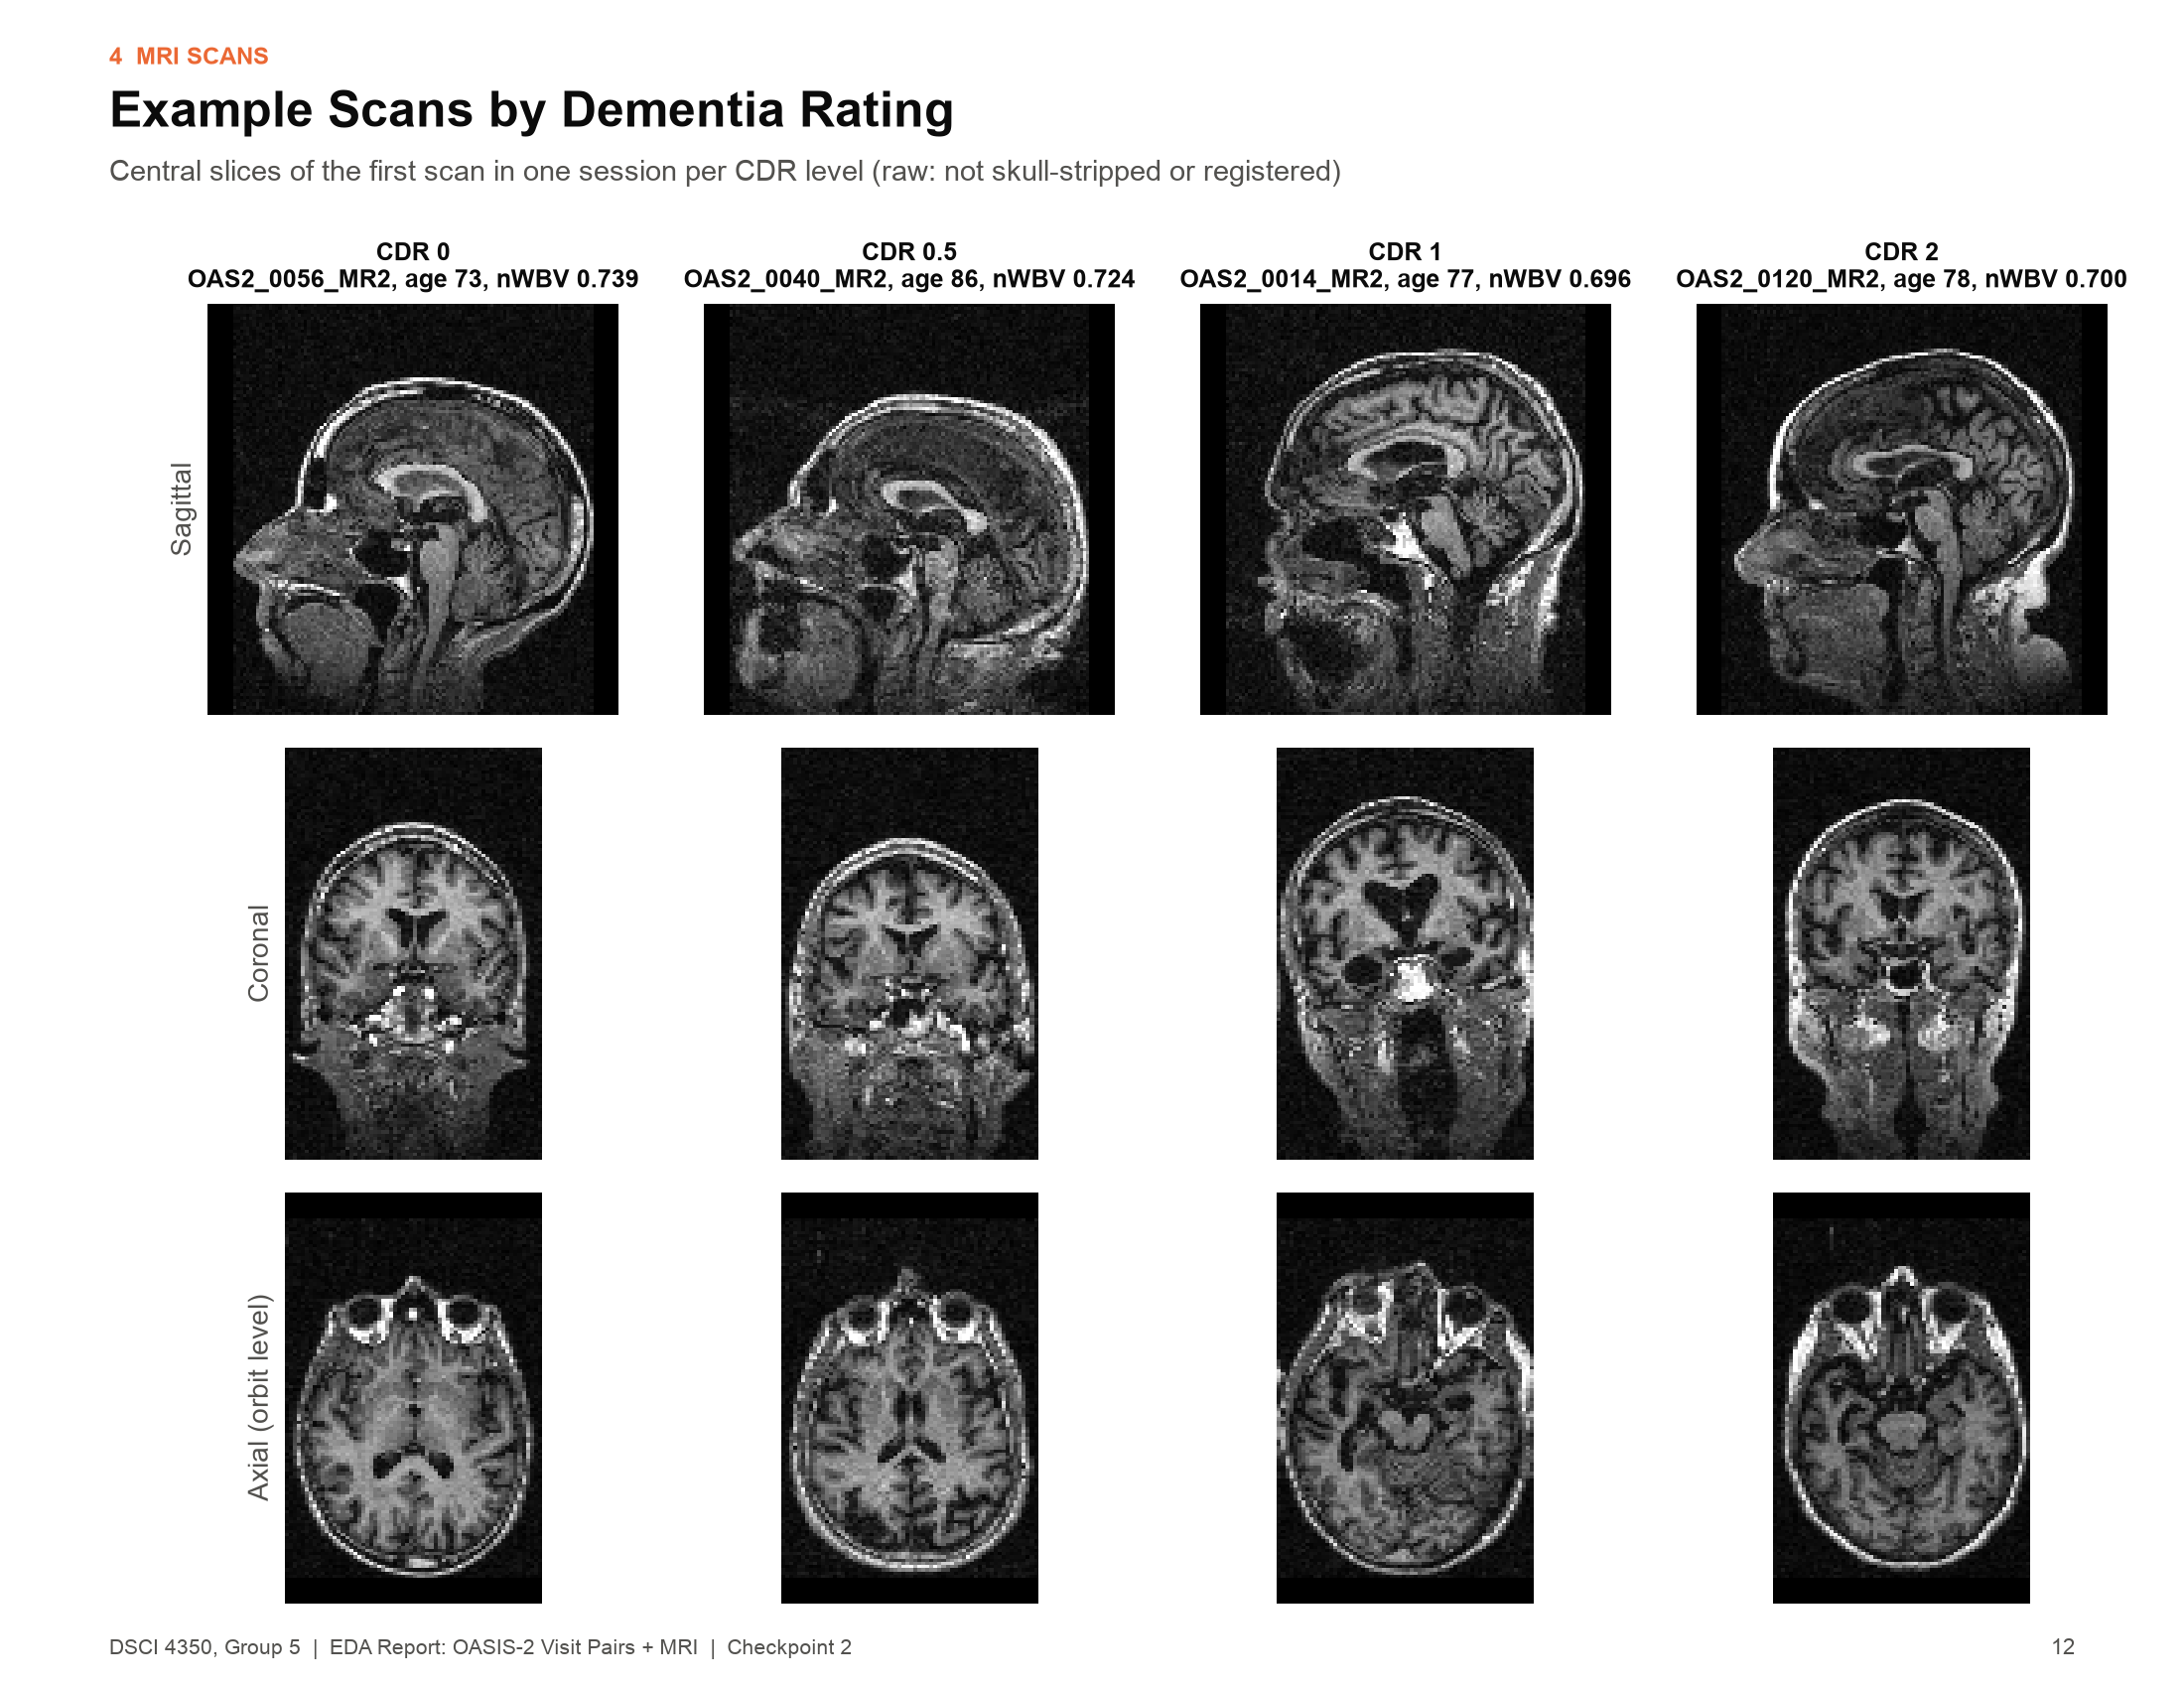

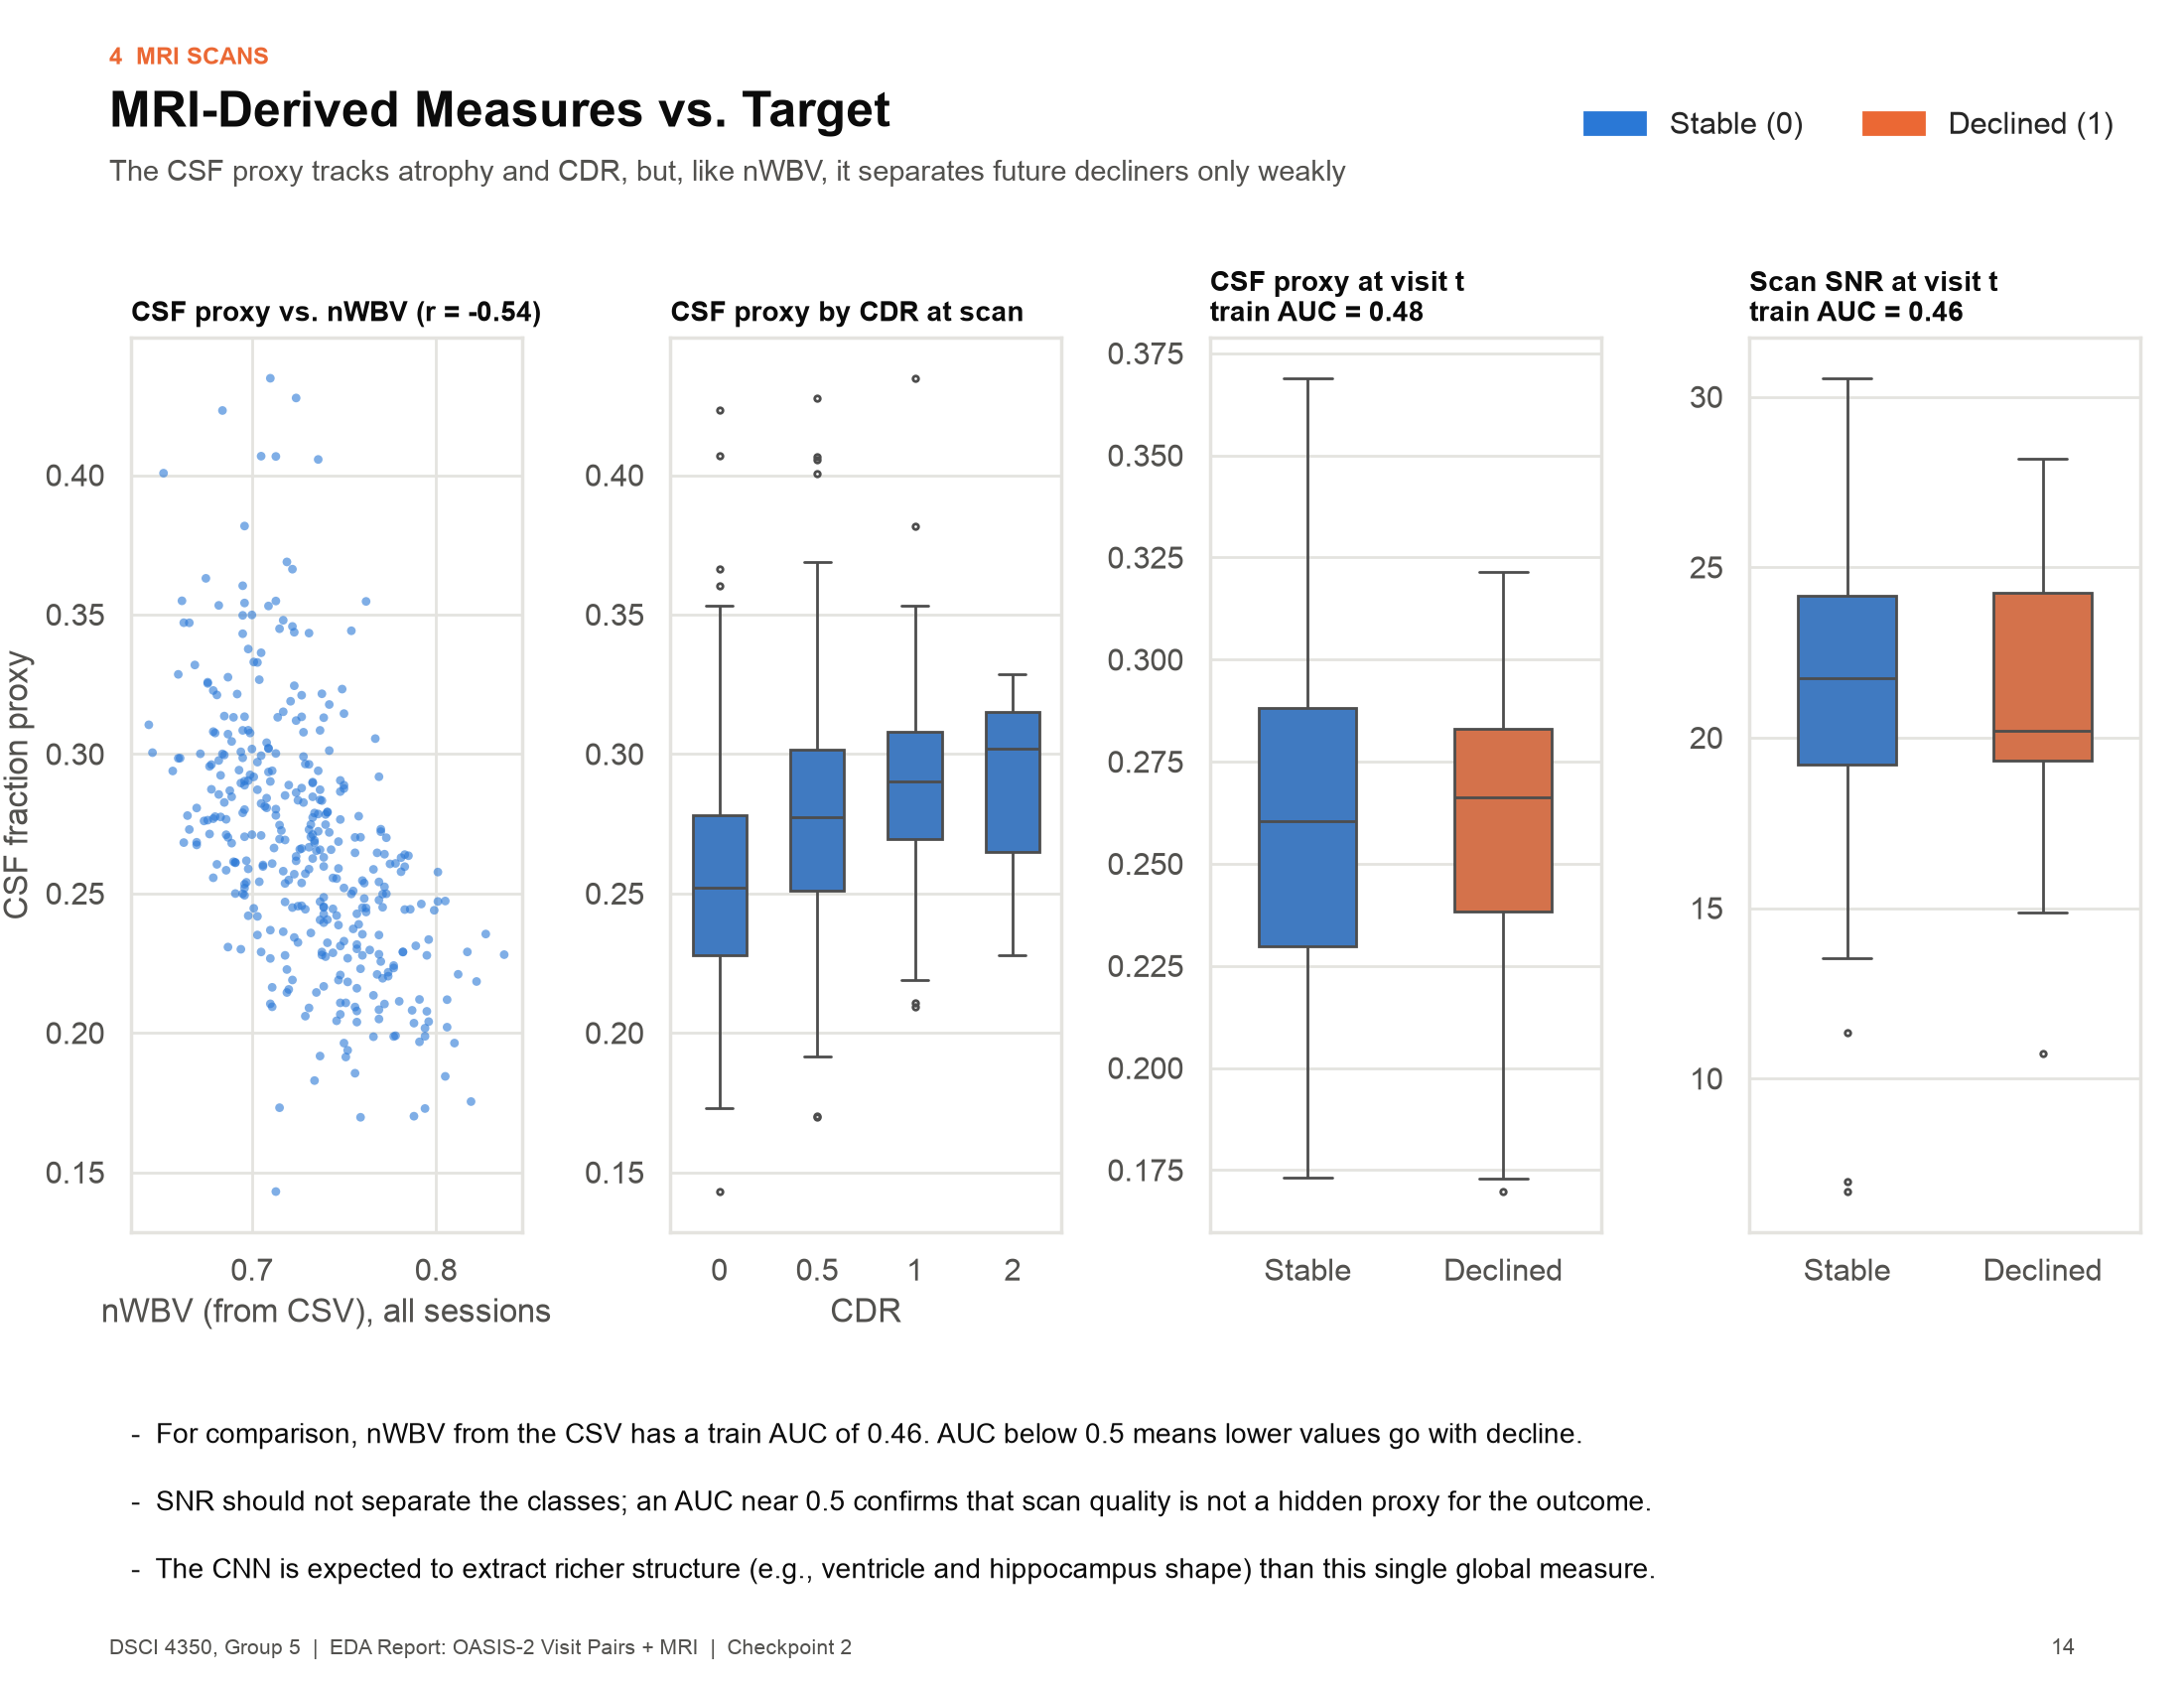

In [22]:
for name in ["05_target_balance.png", "08_feature_vs_target.png", "10_univariate_auc.png",
             "12_mri_examples.png", "14_mri_vs_target.png"]:
    show_figure(name)

---
# Part 3: MRI Volumes for the CNNs
Each raw scan is 256 × 256 × 128 voxels. `make_mri_volumes` keeps the first T1 scan of every session, averages 2 × 4 × 4 voxel blocks (→ 64 × 64 × 64), z-scores the intensities on head voxels (so scanner gain differences cancel out), and clips at ±5 SD.

In [23]:
t0 = time.perf_counter()
make_mri_volumes.main()
print(f"Runtime: {(time.perf_counter() - t0) / 60:.1f} min")
volumes = make_mri_volumes.load_volumes()

Wrote 373 volumes of shape (64, 64, 64) to /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/data/interim/oasis2_mri_volumes.npz
Runtime: 1.6 min


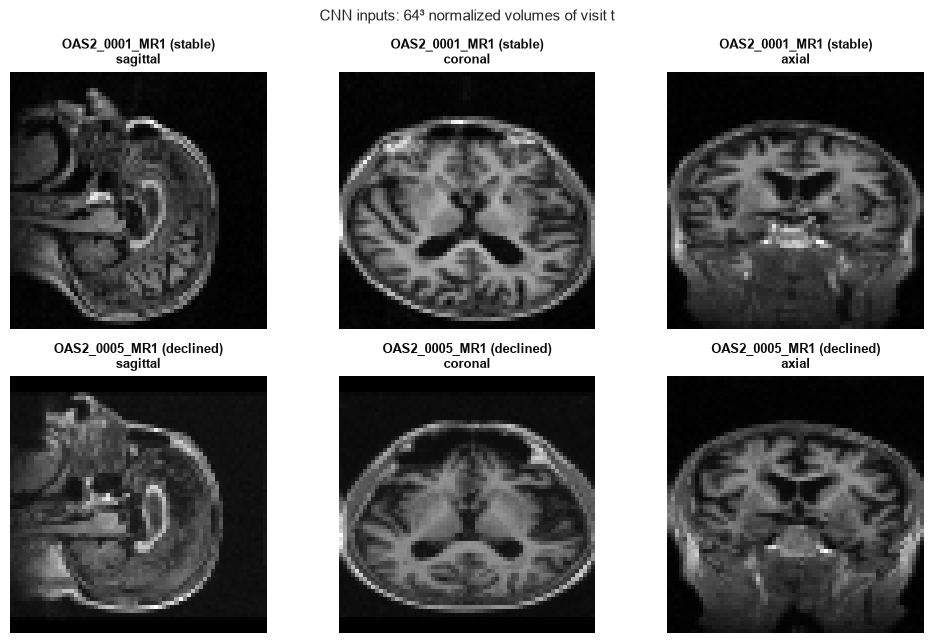

In [24]:
# One stable and one declined training patient, three orthogonal mid-slices each
train_pairs = pairs.query("split == 'train'")
examples = [train_pairs.query("declined == 0").iloc[0], train_pairs.query("declined == 1").iloc[0]]
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for row, ex in zip(axes, examples):
    v = volumes[ex.mri_id]
    for ax, img, view in zip(row, [v[32], v[:, 32], v[:, :, 32]], ["sagittal", "coronal", "axial"]):
        ax.imshow(np.rot90(img), cmap="gray"); ax.axis("off")
        ax.set_title(f"{ex.mri_id} ({'declined' if ex.declined else 'stable'})\n{view}", fontsize=9)
plt.suptitle("CNN inputs: 64³ normalized volumes of visit t")
plt.tight_layout(); plt.show()

---
# Part 4: Modeling, Baselines (Model 2: metadata-only)
Re-run of `notebooks/02_baseline_models.ipynb` (without the Weights & Biases logging). Every model is scored with the shared function `src.models.evaluate.evaluate_model`: **patient-grouped 5-fold CV on the training patients, metrics on the pooled out-of-fold predictions**.

Feature sets:
- **metadata-only**: demographics, MMSE, CDR, CSV brain volumes, visit timing and change features (Model 2). `asf` is dropped because it is computed from `etiv` (r = −0.99).
- **mri-measures (tabular)**: brain-volume measures only, a simple imaging baseline that the CNN should beat.
- **combined**: metadata + the MRI scan measure computed from the raw scans.

`class_weight="balanced"` weights the rare declined class (14%) about 6:1. A dummy model that always predicts the prior is the floor.

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

train = pairs[pairs["split"] == "train"]
print(f"Training pairs: {len(train)} from {train['subject_id'].nunique()} patients")
print(f"Declined: {train['declined'].sum()} ({train['declined'].mean():.1%})")

metadata = config.MODEL_METADATA_FEATURES
feature_sets = {
    "metadata-only": metadata,
    "mri-measures (tabular)": ["etiv", "nwbv", "nwbv_change_prev", "nwbv_rate_prev", "mri_csf_proxy"],
    "combined": metadata + config.MRI_SCAN_FEATURES,
}
models = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic_regression": make_pipeline(StandardScaler(),
                                         LogisticRegression(class_weight="balanced", max_iter=1000)),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight="balanced", random_state=42),
    "gradient_boosting": HistGradientBoostingClassifier(max_depth=3, class_weight="balanced",
                                                        random_state=42),
}

Training pairs: 178 from 119 patients
Declined: 25 (14.0%)


In [26]:
rows = []
for set_name, features in feature_sets.items():
    for model_name, model in models.items():
        rows.append({"feature_set": set_name, "model": model_name,
                     **evaluate.evaluate_model(model, features)})
baseline_results = pd.DataFrame(rows).round(3)
baseline_results.to_csv(config.REPORTS_DIR / "baseline_results.csv", index=False)
baseline_results

,feature_set,model,roc_auc,pr_auc,recall,precision,f1,accuracy
0,metadata-only,dummy,0.496,0.140,0.00,0.000,0.000,0.860
1,metadata-only,logistic_regression,0.578,0.180,0.40,0.152,0.220,0.601
2,metadata-only,random_forest,0.559,0.225,0.28,0.149,0.194,0.674
3,metadata-only,gradient_boosting,0.525,0.199,0.20,0.161,0.179,0.742
4,mri-measures (tabular),dummy,0.496,0.140,0.00,0.000,0.000,0.860
5,mri-measures (tabular),logistic_regression,0.603,0.176,0.64,0.182,0.283,0.545
6,mri-measures (tabular),random_forest,0.620,0.228,0.56,0.250,0.346,0.702
7,mri-measures (tabular),gradient_boosting,0.564,0.180,0.28,0.167,0.209,0.702
8,combined,dummy,0.496,0.140,0.00,0.000,0.000,0.860
9,combined,logistic_regression,0.562,0.181,0.32,0.119,0.174,0.573


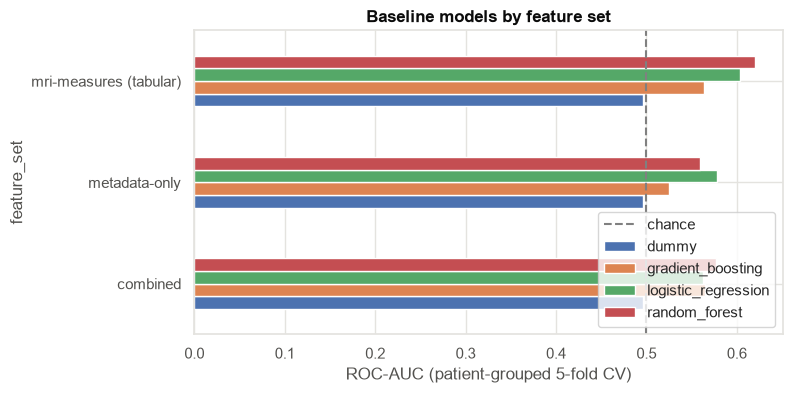

In [27]:
baseline_results.pivot(index="feature_set", columns="model", values="roc_auc").plot.barh(figsize=(8, 4))
plt.axvline(0.5, color="gray", linestyle="--", label="chance")
plt.xlabel("ROC-AUC (patient-grouped 5-fold CV)")
plt.title("Baseline models by feature set")
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "15_baseline_comparison.png", dpi=150)
plt.show()

### Error analysis
Confusion matrix of the best untuned baseline (0.5 threshold) and the declined patients it ranked lowest.

Best baseline: random_forest on mri-measures (tabular) (ROC-AUC 0.62)


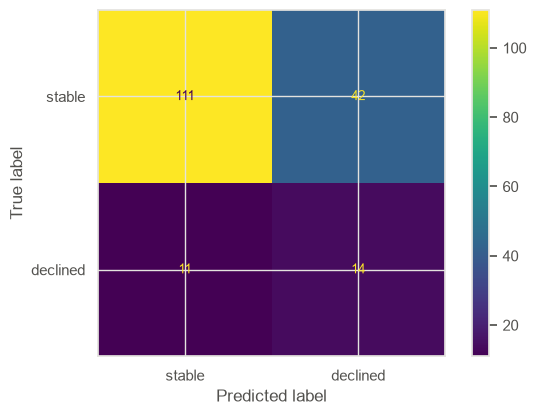

,subject_id,cdr,mmse,age,predicted_risk
207,OAS2_0176,0.0,30.0,87,0.03
21,OAS2_0018,0.0,29.0,88,0.09
51,OAS2_0041,0.0,28.0,73,0.12
178,OAS2_0145,0.0,30.0,68,0.13
57,OAS2_0046,0.5,20.0,83,0.17
148,OAS2_0118,0.0,30.0,67,0.35
35,OAS2_0031,0.0,30.0,88,0.35
119,OAS2_0092,0.0,28.0,83,0.36
143,OAS2_0114,0.5,27.0,76,0.40
22,OAS2_0020,0.0,29.0,80,0.41


In [28]:
best = baseline_results[baseline_results["model"] != "dummy"].sort_values("roc_auc", ascending=False).iloc[0]
print(f"Best baseline: {best['model']} on {best['feature_set']} (ROC-AUC {best['roc_auc']})")
features = feature_sets[best["feature_set"]]
probs = cross_val_predict(models[best["model"]], train[features], train["declined"],
                          cv=PredefinedSplit(train["cv_fold"]), method="predict_proba")[:, 1]
ConfusionMatrixDisplay.from_predictions(train["declined"], (probs >= 0.5).astype(int),
                                        display_labels=["stable", "declined"])
plt.show()
missed = train.assign(predicted_risk=probs.round(2)).query("declined == 1")
missed.sort_values("predicted_risk")[["subject_id", "cdr", "mmse", "age", "predicted_risk"]].head(10)

---
# Part 5: Modeling, 3D CNNs (Model 1: MRI-only, Model 3: multimodal)
**Architecture** (`src/models/cnn.py`): 4 blocks of Conv3d(3×3×3) + BatchNorm + ReLU + 2× max pooling (channels 8-16-32-64), global average pooling, dropout 0.3, linear head, about 73k parameters (kept deliberately small for 178 training volumes). **Model 3** adds a Linear(18 → 16) + ReLU branch for the standardized metadata and concatenates it with the 64-d MRI embedding (late fusion).

**Training:** AdamW (lr 1e-3, weight decay 1e-4), batch size 8, 10 epochs, class-weighted BCE (`pos_weight` ≈ 6), random left-right flips and ±3-voxel shifts, seed 42. Same patient-grouped folds and metrics as the baselines. A fixed number of epochs (no early stopping on the validation fold), so the out-of-fold scores are not tuned on the data they measure.

In [29]:
cnn_results = {}
for model_name in ["mri", "multimodal"]:
    cfg = train_cnn.TrainConfig(model=model_name)
    print(f"=== {train_cnn.FEATURE_SET_NAMES[model_name]} | device {cfg.device} ===")
    result = train_cnn.cross_validate(cfg)
    train_cnn.save_results(cfg, result)  # appends to reports/cnn_results.csv, writes OOF predictions
    cnn_results[model_name] = result
    print({k: round(v, 3) for k, v in result["metrics"].items()})
    print(f"{result['timing']['parameters']:,} parameters, "
          f"{result['timing']['mean_epoch_seconds']:.1f} s/epoch, "
          f"{result['timing']['total_cv_seconds'] / 60:.1f} min for 5 folds\n")

=== mri-volume (CNN) | device cpu ===


fold 0: val ROC-AUC 0.626 (60 s)


fold 1: val ROC-AUC 0.523 (60 s)


fold 2: val ROC-AUC 0.247 (60 s)


fold 3: val ROC-AUC 0.660 (61 s)


fold 4: val ROC-AUC 0.477 (87 s)
{'roc_auc': 0.52, 'pr_auc': 0.166, 'recall': 0.6, 'precision': 0.149, 'f1': 0.238, 'accuracy': 0.461}
73,097 parameters, 6.5 s/epoch, 5.5 min for 5 folds

=== mri-volume + metadata (CNN) | device cpu ===


fold 0: val ROC-AUC 0.606 (135 s)


fold 1: val ROC-AUC 0.626 (70 s)


fold 2: val ROC-AUC 0.227 (60 s)


fold 3: val ROC-AUC 0.747 (61 s)


fold 4: val ROC-AUC 0.465 (59 s)
{'roc_auc': 0.522, 'pr_auc': 0.184, 'recall': 0.56, 'precision': 0.151, 'f1': 0.237, 'accuracy': 0.494}
73,417 parameters, 7.7 s/epoch, 6.4 min for 5 folds



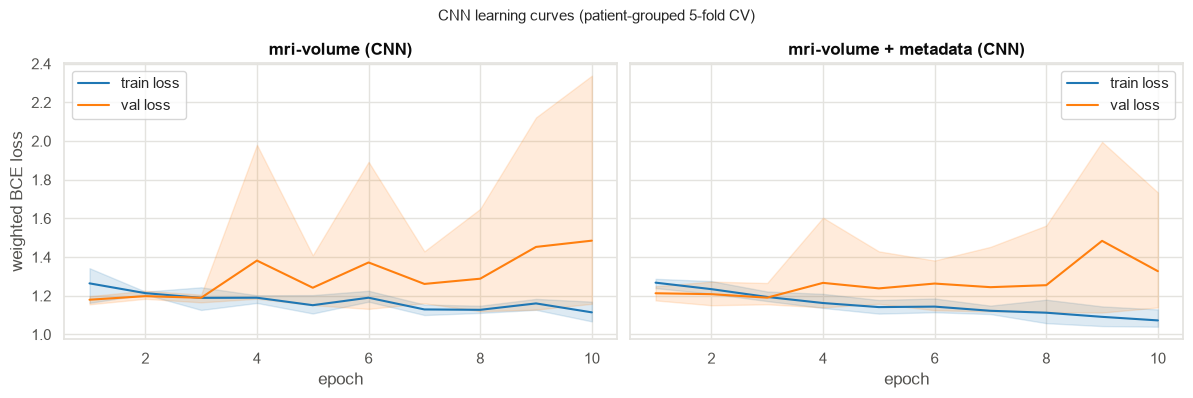

Validation ROC-AUC per fold (final epoch):


,mri-volume (CNN),mri-volume + metadata (CNN)
fold,,
0,0.626,0.606
1,0.523,0.626
2,0.247,0.227
3,0.660,0.747
4,0.477,0.465


In [30]:
# Learning curves: mean over the 5 folds (shaded = min/max across folds)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, res) in zip(axes, cnn_results.items()):
    h = pd.concat([pd.DataFrame(fold).assign(fold=i) for i, fold in enumerate(res["histories"])])
    for col, color in [("train_loss", "tab:blue"), ("val_loss", "tab:orange")]:
        g = h.groupby("epoch")[col]
        ax.plot(g.mean().index, g.mean(), color=color, label=col.replace("_", " "))
        ax.fill_between(g.mean().index, g.min(), g.max(), color=color, alpha=0.15)
    ax.set_title(train_cnn.FEATURE_SET_NAMES[name]); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("weighted BCE loss")
plt.suptitle("CNN learning curves (patient-grouped 5-fold CV)"); plt.tight_layout(); plt.show()

fold_auc = pd.DataFrame({train_cnn.FEATURE_SET_NAMES[n]: [f[-1]["val_roc_auc"] for f in r["histories"]]
                         for n, r in cnn_results.items()}).rename_axis("fold").round(3)
print("Validation ROC-AUC per fold (final epoch):")
fold_auc

---
# Part 6: Hyperparameter Optimization (Optuna)
**Method:** Optuna, TPE sampler (seed 42), **30 trials per model and feature set**. The objective of each trial is the **pooled out-of-fold ROC-AUC** of the same patient-grouped 5-fold CV. Every trial's recall, precision, F1 and PR-AUC are stored too.

| Model | Search space |
|---|---|
| Logistic regression | C ∈ [0.001, 10] (log), penalty L1 or L2 |
| Random forest | trees 100 to 600, max depth 2 to 12, min samples per leaf 1 to 20, max features 0.2 to 1.0 |
| Gradient boosting | learning rate 0.01 to 0.3 (log), iterations 50 to 400, max depth 2 to 6, min samples per leaf 5 to 40, L2 1e-4 to 10 (log) |

The best trial's score is **optimistic** (the same folds pick and score the hyperparameters); the held-out test set in Part 9 gives the unbiased estimate. The CNNs were not tuned (each trial is a full 5-fold CV of a 3D CNN, about 10 hours for the planned 40 trials on this laptop); see `reports/experiment_plan.md`.

In [31]:
from datetime import datetime, timezone
optuna.logging.set_verbosity(optuna.logging.WARNING)
N_TRIALS = 30
tuning_rows, studies = [], {}
for set_name, features in tune.FEATURE_SETS.items():
    for model_name in tune.MODEL_SPACES:
        t0 = time.perf_counter()
        study = tune.tune(model_name, features, N_TRIALS)
        seconds = time.perf_counter() - t0
        studies[(set_name, model_name)] = study
        best_trial = study.best_trial
        tuning_rows.append({"feature_set": set_name, "model": model_name,
                            **{k: round(v, 3) for k, v in best_trial.user_attrs.items()},
                            "trials": N_TRIALS, "seconds": round(seconds, 1),
                            "seconds_per_trial": round(seconds / N_TRIALS, 2),
                            "best_params": best_trial.params})
        print(f"{set_name:>14} | {model_name:<20} best ROC-AUC {best_trial.value:.3f}  ({seconds:.0f} s)")
tuning_results = pd.DataFrame(tuning_rows)
tuning_results["created_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
tuning_results.to_csv(config.TUNING_RESULTS_CSV, index=False)

 metadata-only | logistic_regression  best ROC-AUC 0.578  (3 s)


 metadata-only | random_forest        best ROC-AUC 0.616  (41 s)


 metadata-only | gradient_boosting    best ROC-AUC 0.655  (86 s)


      combined | logistic_regression  best ROC-AUC 0.568  (2 s)


      combined | random_forest        best ROC-AUC 0.643  (66 s)


      combined | gradient_boosting    best ROC-AUC 0.648  (31 s)


In [32]:
# Before vs. after tuning (same folds, same metric)
before = baseline_results.set_index(["feature_set", "model"])["roc_auc"].rename("untuned_roc_auc")
compare = tuning_results.set_index(["feature_set", "model"])[["roc_auc", "pr_auc", "recall", "precision", "f1"]]
compare = compare.rename(columns={"roc_auc": "tuned_roc_auc"}).join(before)
compare.insert(1, "gain", (compare["tuned_roc_auc"] - compare["untuned_roc_auc"]).round(3))
display(compare)
pd.set_option("display.max_colwidth", 200)
display(tuning_results[["feature_set", "model", "best_params"]])

tuned_roc_auc   gain  pr_auc  recall  precision     f1  untuned_roc_auc
feature_set   model                                                                                       
metadata-only logistic_regression          0.578  0.000   0.180    0.40      0.152  0.220            0.578
              random_forest                0.616  0.057   0.278    0.40      0.222  0.286            0.559
              gradient_boosting            0.655  0.130   0.286    0.40      0.222  0.286            0.525
combined      logistic_regression          0.568  0.006   0.204    0.32      0.119  0.174            0.562
              random_forest                0.643  0.066   0.288    0.28      0.241  0.259            0.577
              gradient_boosting            0.648  0.083   0.314    0.28      0.333  0.304            0.565

,feature_set,model,best_params
0,metadata-only,logistic_regression,"{'penalty': 'l2', 'C': 1.0462816792275733}"
1,metadata-only,random_forest,"{'n_estimators': 300, 'max_depth': 5, 'min_samples_leaf': 1, 'max_features': 0.7352345408602358}"
2,metadata-only,gradient_boosting,"{'learning_rate': 0.011137636314567354, 'max_iter': 250, 'max_depth': 4, 'min_samples_leaf': 5, 'l2_regularization': 0.020170143712815673}"
3,combined,logistic_regression,"{'penalty': 'l2', 'C': 0.09108064139022445}"
4,combined,random_forest,"{'n_estimators': 600, 'max_depth': 8, 'min_samples_leaf': 1, 'max_features': 0.7776006453301492}"
5,combined,gradient_boosting,"{'learning_rate': 0.22787915138033604, 'max_iter': 100, 'max_depth': 2, 'min_samples_leaf': 5, 'l2_regularization': 0.0447080826450044}"


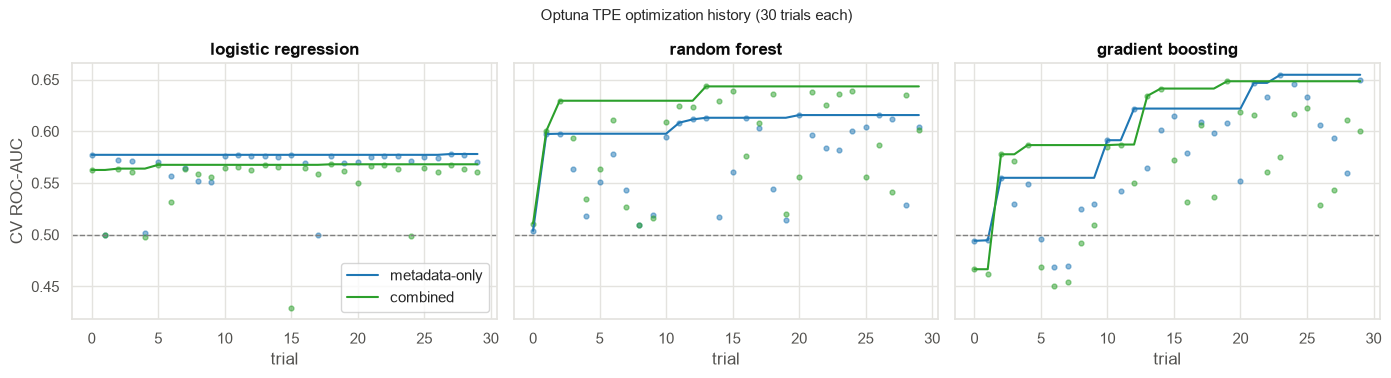

In [33]:
# Optimization history: every trial's CV ROC-AUC and the running best
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, model_name in zip(axes, tune.MODEL_SPACES):
    for set_name, color in [("metadata-only", "tab:blue"), ("combined", "tab:green")]:
        values = [t.value for t in studies[(set_name, model_name)].trials]
        ax.scatter(range(len(values)), values, s=12, color=color, alpha=0.5)
        ax.plot(np.maximum.accumulate(values), color=color, label=set_name)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(model_name.replace("_", " ")); ax.set_xlabel("trial")
axes[0].set_ylabel("CV ROC-AUC"); axes[0].legend(loc="lower right")
plt.suptitle("Optuna TPE optimization history (30 trials each)"); plt.tight_layout(); plt.show()

---
# Part 7: Cross-Validated Comparison of All Models
All numbers in this part come from patient-grouped 5-fold CV on the training patients. **Model selection happens here**, before the test set is opened: the model with the highest CV ROC-AUC, the tuned gradient boosting on metadata, is the selected model.

Saved /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/reports/figures/16_model_comparison.png


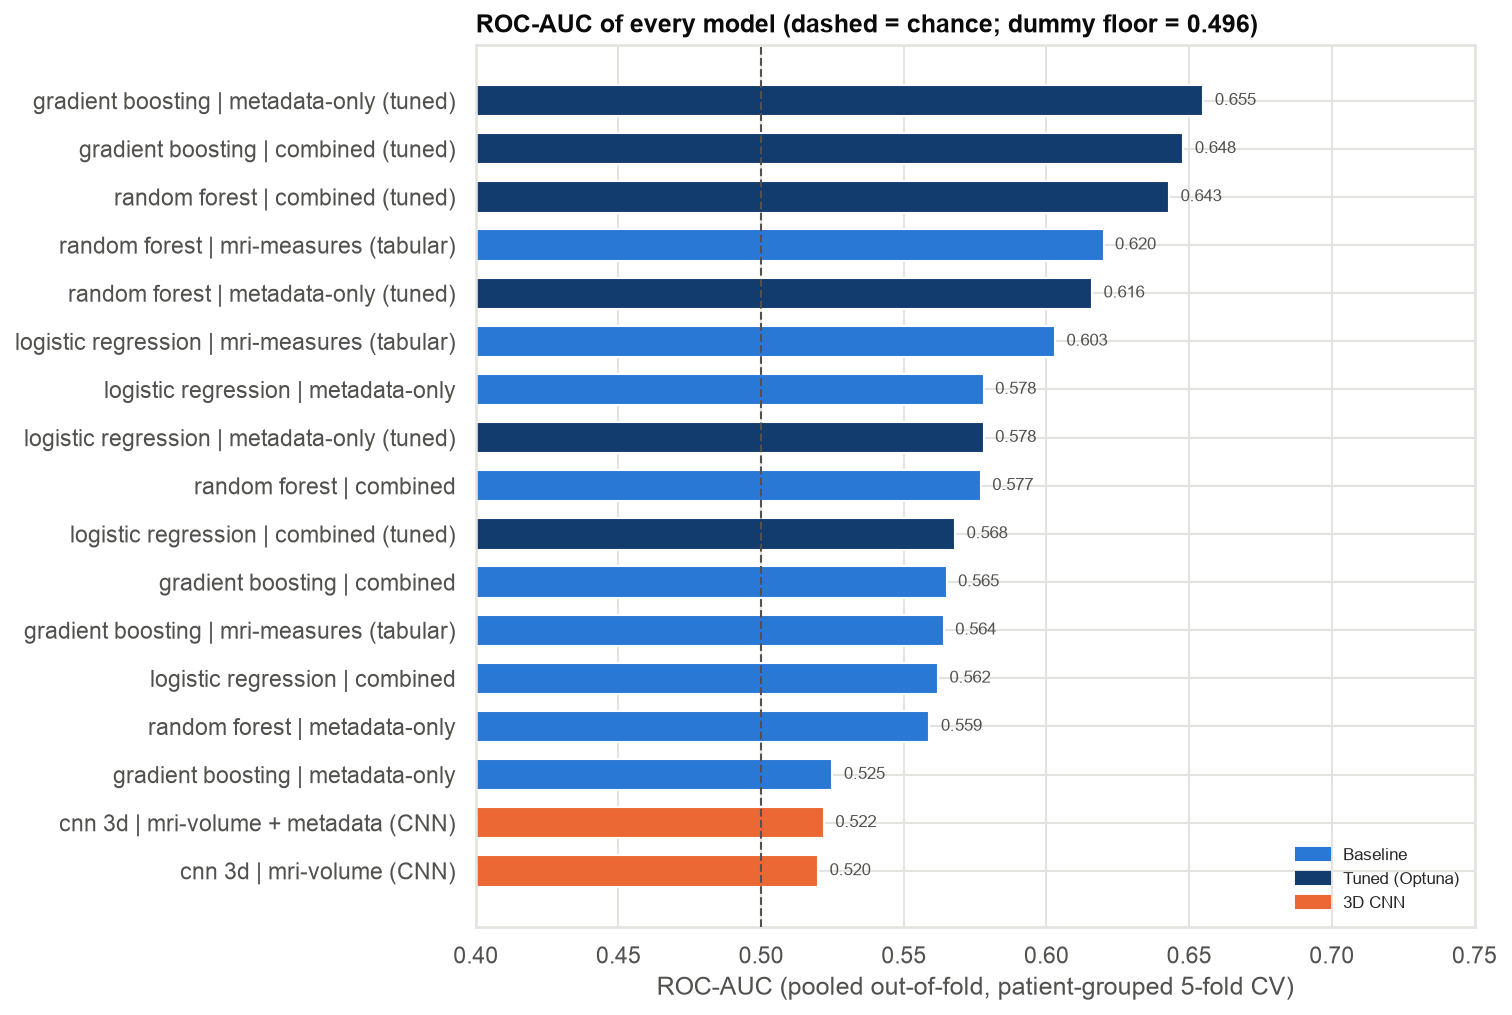

,stage,feature_set,model,roc_auc,pr_auc,recall,precision,f1,accuracy
0,tuned,metadata-only,gradient_boosting,0.655,0.286,0.40,0.222,0.286,0.719
1,tuned,combined,gradient_boosting,0.648,0.314,0.28,0.333,0.304,0.820
2,tuned,combined,random_forest,0.643,0.288,0.28,0.241,0.259,0.775
3,baseline,mri-measures (tabular),random_forest,0.620,0.228,0.56,0.250,0.346,0.702
4,tuned,metadata-only,random_forest,0.616,0.278,0.40,0.222,0.286,0.719
5,baseline,mri-measures (tabular),logistic_regression,0.603,0.176,0.64,0.182,0.283,0.545
6,tuned,metadata-only,logistic_regression,0.578,0.180,0.40,0.152,0.220,0.601
7,baseline,metadata-only,logistic_regression,0.578,0.180,0.40,0.152,0.220,0.601
8,baseline,combined,random_forest,0.577,0.253,0.32,0.182,0.232,0.702
9,tuned,combined,logistic_regression,0.568,0.204,0.32,0.119,0.174,0.573


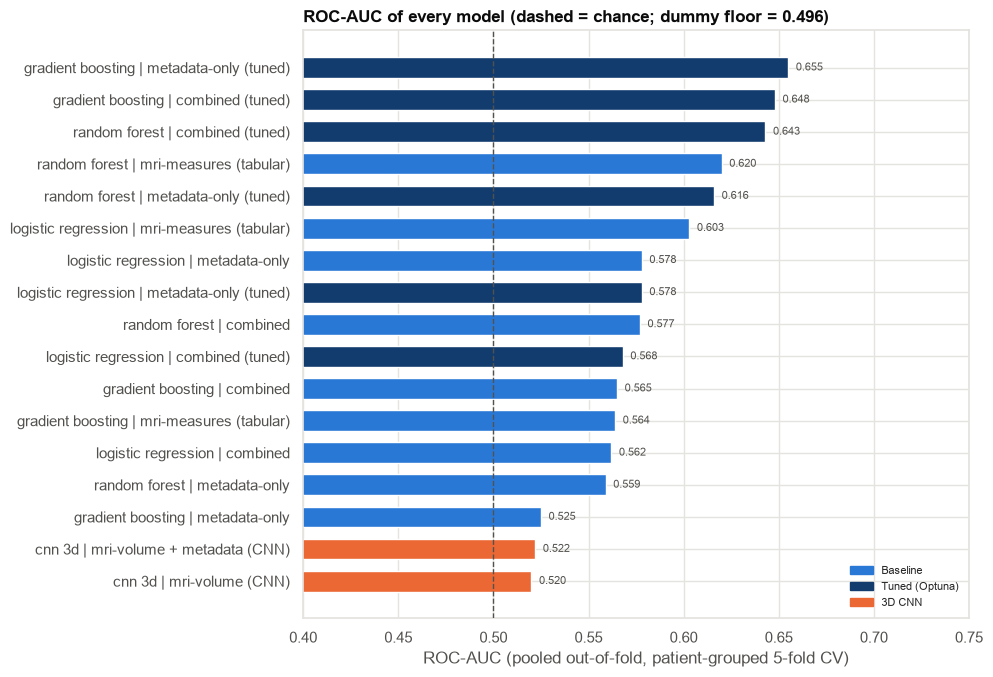

In [34]:
model_comparison.main()
show_figure("16_model_comparison.png")
cv_table = model_comparison.load_results().sort_values("roc_auc", ascending=False)
cv_table[["stage", "feature_set", "model", "roc_auc", "pr_auc", "recall", "precision", "f1", "accuracy"]].reset_index(drop=True)

---
# Part 8: Monitoring (Data Quality, Drift, Calibration, Subgroups)
`src/monitoring/drift.py` treats the test patients' **features** (not their labels) as a "new batch" and compares them with the training patients: data-quality checks, PSI and Kolmogorov-Smirnov drift per feature (with a permutation threshold because PSI is biased for small batches), and the CNNs' calibration (Brier score) and ROC-AUC by sex and age band.

In [35]:
drift.main()

Data quality: ok
Feature drift: {'ok': 15, 'alert': 4, 'warn': 1}
        feature    psi  psi_null_p95  ks_statistic  ks_pvalue  mean_shift_sd status
            ses 0.3865        0.2720        0.1698     0.2213          0.149  alert
            age 0.3331        0.4342        0.1439     0.3992          0.005     ok
   days_to_next 0.3070        0.4507        0.2634     0.0106         -0.337     ok
           nwbv 0.2989        0.4552        0.1536     0.3253         -0.137     ok
  mri_csf_proxy 0.2979        0.4089        0.1733     0.2023          0.040     ok
           etiv 0.2902        0.4456        0.1567     0.3038          0.122     ok
days_since_prev 0.2888        0.1982        0.1690     0.2259         -0.150  alert
    ses_imputed 0.2875        0.1168        0.1331     0.4957          0.898  alert
cnn_mri (out-of-fold, train): ROC-AUC 0.520, Brier 0.304, subgroups {'sex': {'female': 0.599, 'male': 0.425}, 'age_band': {'<70': 0.554, '70-79': 0.458, '80+': 0.582}} -> alert
c

In [36]:
report = json.loads(config.MONITORING_REPORT.read_text())
display(pd.DataFrame(report["feature_drift"]).round(3).head(10))
perf = pd.DataFrame({k: {"roc_auc": round(v["roc_auc"], 3), "brier": round(v["brier"], 3),
                         **{f"AUC {g}={k2}": a for g, d in v["subgroups"].items() for k2, a in d.items()},
                         "status": v["status"]}
                     for k, v in report["model_performance"].items()}).T
perf

,feature,psi,psi_null_p95,ks_statistic,ks_pvalue,mean_shift_sd,status
0,ses,0.386,0.272,0.170,0.221,0.149,alert
1,age,0.333,0.434,0.144,0.399,0.005,ok
2,days_to_next,0.307,0.451,0.263,0.011,-0.337,ok
3,nwbv,0.299,0.455,0.154,0.325,-0.137,ok
4,mri_csf_proxy,0.298,0.409,0.173,0.202,0.040,ok
5,etiv,0.290,0.446,0.157,0.304,0.122,ok
6,days_since_prev,0.289,0.198,0.169,0.226,-0.150,alert
7,ses_imputed,0.288,0.117,0.133,0.496,0.898,alert
8,asf,0.268,0.420,0.157,0.304,-0.090,ok
9,days_since_baseline,0.265,0.226,0.175,0.194,-0.093,alert


,roc_auc,brier,AUC sex=female,AUC sex=male,AUC age_band=<70,AUC age_band=70-79,AUC age_band=80+,status
"cnn_mri (out-of-fold, train)",0.52,0.304,0.599,0.425,0.554,0.458,0.582,alert
"cnn_multimodal (out-of-fold, train)",0.522,0.288,0.594,0.431,0.571,0.448,0.59,alert


---
# Part 9: Final Evaluation on the Held-Out Test Patients
This is the only step that uses the test labels. **31 patients, 45 visit pairs, 6 declines**, none of them seen in any earlier step.

Protocol (`src/models/final_evaluation.py`):
1. Each candidate is refit on all 178 training pairs with the settings chosen by CV (tuned hyperparameters from Part 6; the CNN configuration from Part 5).
2. CNNs are trained with **3 seeds** (42, 43, 44) and their test predictions averaged; the per-seed spread shows training noise.
3. **Metrics:** ROC-AUC (primary), PR-AUC (chance = 6/45 = 0.13), Brier score, and recall / precision / F1 at two thresholds: 0.5, and a threshold chosen on the **training out-of-fold predictions** with Youden's J (best sensitivity + specificity). The test set never chooses a model or a threshold.
4. **Uncertainty:** 1,000 **patient-level bootstrap** resamples (whole patients are resampled, so a patient's pairs stay together) → 95% confidence intervals.
5. **Sensitivity analysis:** ROC-AUC again without the pairs whose MRI failed quality control.

In [37]:
t0 = time.perf_counter()
fe = final_evaluation
train_df, test_df = fe.load_splits()
print(f"Test set: {len(test_df)} pairs, {test_df.subject_id.nunique()} patients, "
      f"{test_df.declined.sum()} declines ({test_df.declined.mean():.1%})")
final_models = fe.evaluate_tabular(train_df, test_df)
final_models.update(fe.evaluate_cnns(train_df, test_df))
test_results, boot = fe.summarize(train_df, test_df, final_models)
fe.save(test_df, final_models, test_results)
print(f"Runtime: {(time.perf_counter() - t0) / 60:.1f} min")

Test set: 45 pairs, 31 patients, 6 declines (13.3%)


  3D CNN | MRI volume, seed 42: test ROC-AUC 0.483


  3D CNN | MRI volume, seed 43: test ROC-AUC 0.513


  3D CNN | MRI volume, seed 44: test ROC-AUC 0.509


  3D CNN + metadata | MRI volume + metadata, seed 42: test ROC-AUC 0.641


  3D CNN + metadata | MRI volume + metadata, seed 43: test ROC-AUC 0.645


  3D CNN + metadata | MRI volume + metadata, seed 44: test ROC-AUC 0.744


Saved /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/reports/test_results.csv, /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/reports/test_predictions.csv, /Users/cinthiaochoa/Desktop/DataScience_Project/Predicting-Alzheimer-s-Disease-Progression/reports/test_summary.json
Runtime: 7.9 min


In [38]:
cols = ["model", "selected", "cv_roc_auc", "test_roc_auc", "roc_auc_ci_low", "roc_auc_ci_high",
        "test_pr_auc", "pr_auc_ci_low", "pr_auc_ci_high", "test_brier"]
test_results[cols].round(3)

,model,selected,cv_roc_auc,test_roc_auc,roc_auc_ci_low,roc_auc_ci_high,test_pr_auc,pr_auc_ci_low,pr_auc_ci_high,test_brier
0,logistic_regression | combined (tuned),False,0.568,0.816,0.597,0.965,0.400,0.166,0.844,0.226
1,random_forest | metadata-only (tuned),False,0.616,0.795,0.575,0.953,0.379,0.133,0.784,0.174
2,logistic_regression | metadata-only (tuned),False,0.578,0.791,0.624,0.937,0.304,0.129,0.713,0.229
3,gradient_boosting | metadata-only (tuned),True,0.655,0.769,0.581,0.922,0.364,0.111,0.761,0.167
4,gradient_boosting | combined (tuned),False,0.648,0.726,0.500,0.898,0.289,0.095,0.633,0.171
5,3D CNN + metadata | MRI volume + metadata,False,0.522,0.692,0.430,0.901,0.264,0.088,0.645,0.244
6,random_forest | combined (tuned),False,0.643,0.667,0.404,0.913,0.282,0.083,0.668,0.170
7,dummy (always prior),False,0.496,0.500,0.500,0.500,0.133,0.042,0.246,0.116
8,3D CNN | MRI volume,False,0.520,0.496,0.224,0.752,0.149,0.057,0.388,0.242


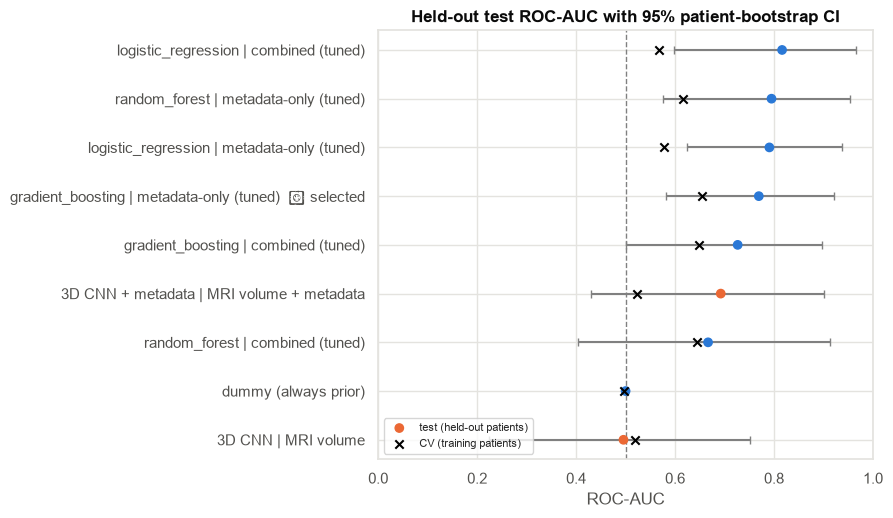

In [39]:
# Forest plot: test ROC-AUC with 95% patient-bootstrap CI, next to the CV estimate
r = test_results.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 0.45 * len(r) + 1.2))
colors = r["family"].map({"tabular": "#2a78d6", "cnn": "#eb6834"})
ax.errorbar(r["test_roc_auc"], r.index, xerr=[r["test_roc_auc"] - r["roc_auc_ci_low"],
            r["roc_auc_ci_high"] - r["test_roc_auc"]], fmt="none", ecolor="gray", capsize=3)
ax.scatter(r["test_roc_auc"], r.index, color=colors, zorder=3, label="test (held-out patients)")
ax.scatter(r["cv_roc_auc"], r.index, marker="x", color="black", zorder=3, label="CV (training patients)")
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(r.index, [m + ("  ★ selected" if s else "") for m, s in zip(r["model"], r["selected"])])
ax.set_xlabel("ROC-AUC"); ax.set_xlim(0, 1); ax.legend(loc="lower left", fontsize=8)
ax.set_title("Held-out test ROC-AUC with 95% patient-bootstrap CI")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "17_test_roc_auc.png", dpi=150); plt.show()

In [40]:
# Thresholded metrics: default 0.5 vs. Youden threshold chosen on training OOF predictions
thr_cols = ["model", "recall@0.5", "precision@0.5", "f1@0.5", "accuracy@0.5", "flagged@0.5",
            "youden_threshold", "recall@youden", "precision@youden", "f1@youden", "accuracy@youden", "flagged@youden"]
test_results[thr_cols].round(3)

,model,recall@0.5,precision@0.5,f1@0.5,accuracy@0.5,flagged@0.5,youden_threshold,recall@youden,precision@youden,f1@youden,accuracy@youden,flagged@youden
0,logistic_regression | combined (tuned),0.833,0.250,0.385,0.644,20,0.380,1.000,0.194,0.324,0.444,31
1,random_forest | metadata-only (tuned),0.667,0.333,0.444,0.778,12,0.618,0.500,0.500,0.500,0.867,6
2,logistic_regression | metadata-only (tuned),0.833,0.278,0.417,0.689,18,0.394,1.000,0.222,0.364,0.533,27
3,gradient_boosting | metadata-only (tuned),0.333,0.167,0.222,0.689,12,0.177,1.000,0.182,0.308,0.400,33
4,gradient_boosting | combined (tuned),0.333,0.200,0.250,0.733,10,0.017,0.833,0.185,0.303,0.489,27
5,3D CNN + metadata | MRI volume + metadata,0.833,0.185,0.303,0.489,27,0.648,0.167,0.250,0.200,0.822,4
6,random_forest | combined (tuned),0.500,0.273,0.353,0.756,11,0.265,0.667,0.190,0.296,0.578,21
7,dummy (always prior),0.000,0.000,0.000,0.867,0,0.140,1.000,0.133,0.235,0.133,45
8,3D CNN | MRI volume,0.333,0.111,0.167,0.556,18,0.769,0.000,0.000,0.000,0.867,0


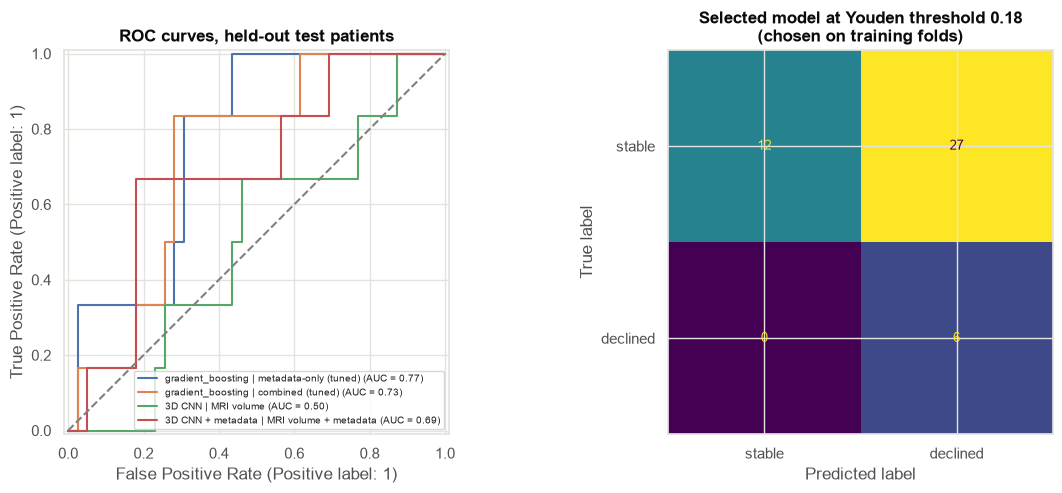

In [41]:
from sklearn.metrics import roc_curve, RocCurveDisplay
y_test = test_df["declined"].to_numpy()
best_cnn = test_results.query("family == 'cnn'").iloc[0]["model"]
shown = [fe.SELECTED_MODEL, "gradient_boosting | combined (tuned)", "3D CNN | MRI volume",
         "3D CNN + metadata | MRI volume + metadata"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in shown:
    RocCurveDisplay.from_predictions(y_test, final_models[name]["test"], name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "--", color="gray"); axes[0].set_title("ROC curves, held-out test patients")
axes[0].legend(fontsize=7, loc="lower right")

sel = test_results.set_index("model").loc[fe.SELECTED_MODEL]
ConfusionMatrixDisplay.from_predictions(y_test, (final_models[fe.SELECTED_MODEL]["test"] >= sel["youden_threshold"]).astype(int),
                                        display_labels=["stable", "declined"], ax=axes[1], colorbar=False)
axes[1].set_title(f"Selected model at Youden threshold {sel['youden_threshold']:.2f}\n(chosen on training folds)")
plt.tight_layout(); plt.show()

In [42]:
# Paired bootstrap: how often does the selected model beat each other model on the same resample?
wide = boot.pivot(index="draw", columns="model", values="roc_auc")
diff = wide.sub(wide[fe.SELECTED_MODEL], axis=0).mul(-1).drop(columns=fe.SELECTED_MODEL)
paired = pd.DataFrame({"mean_auc_gain_of_selected": diff.mean(),
                       "ci_low": diff.quantile(0.025), "ci_high": diff.quantile(0.975),
                       "P(selected better)": (diff > 0).mean()}).sort_values("mean_auc_gain_of_selected")
print(f"{len(wide)} bootstrap resamples with both classes present")
paired.round(3)

995 bootstrap resamples with both classes present


,mean_auc_gain_of_selected,ci_low,ci_high,P(selected better)
model,,,,
logistic_regression | combined (tuned),-0.056,-0.308,0.261,0.320
logistic_regression | metadata-only (tuned),-0.029,-0.260,0.200,0.381
random_forest | metadata-only (tuned),-0.027,-0.169,0.094,0.342
gradient_boosting | combined (tuned),0.042,-0.108,0.200,0.708
3D CNN + metadata | MRI volume + metadata,0.066,-0.239,0.425,0.647
random_forest | combined (tuned),0.098,-0.143,0.370,0.782
dummy (always prior),0.262,0.081,0.422,0.997
3D CNN | MRI volume,0.263,-0.059,0.627,0.938


In [43]:
# CNN training noise: test ROC-AUC of each seed
display(test_results.query("family == 'cnn'")[["model", "seed_roc_auc_min", "seed_roc_auc_max", "test_roc_auc"]].round(3))
# Sensitivity analysis: drop pairs whose visit-t MRI failed quality control
fe.sensitivity_without_qc_flags(test_df, final_models).round(3)

,model,seed_roc_auc_min,seed_roc_auc_max,test_roc_auc
5,3D CNN + metadata | MRI volume + metadata,0.641,0.744,0.692
8,3D CNN | MRI volume,0.483,0.513,0.496


,model,all_pairs,without_qc_flagged,pairs_dropped
0,dummy (always prior),0.500,0.500,4
1,logistic_regression | metadata-only (tuned),0.791,0.790,4
2,random_forest | metadata-only (tuned),0.795,0.833,4
3,gradient_boosting | metadata-only (tuned),0.769,0.805,4
4,logistic_regression | combined (tuned),0.816,0.824,4
5,random_forest | combined (tuned),0.667,0.710,4
6,gradient_boosting | combined (tuned),0.726,0.762,4
7,3D CNN | MRI volume,0.496,0.457,4
8,3D CNN + metadata | MRI volume + metadata,0.692,0.671,4


In [44]:
# Which test declines were caught or missed by the selected model?
preds = pd.read_csv(fe.TEST_PREDICTIONS_CSV)
preds["selected_risk"] = preds[fe.SELECTED_MODEL]
preds["flagged"] = preds["selected_risk"] >= sel["youden_threshold"]
preds.query("declined == 1")[["subject_id", "mri_id", "cdr", "mmse", "age", "selected_risk", "flagged"]]

,subject_id,mri_id,cdr,mmse,age,selected_risk,flagged
3,OAS2_0007,OAS2_0007_MR1,0.5,28.0,71,0.8106,True
6,OAS2_0014,OAS2_0014_MR1,0.5,21.0,76,0.4450,True
14,OAS2_0054,OAS2_0054_MR1,0.0,29.0,85,0.2934,True
23,OAS2_0089,OAS2_0089_MR1,0.5,29.0,70,0.7889,True
33,OAS2_0133,OAS2_0133_MR1,0.0,29.0,78,0.4893,True
42,OAS2_0181,OAS2_0181_MR1,0.5,26.0,74,0.4391,True


In [45]:
print(f"Total pipeline runtime: {(time.perf_counter() - PIPELINE_START) / 60:.1f} min")

Total pipeline runtime: 28.7 min


---
# Part 10: Conclusions
_Written after the run, from the outputs above._

## 1. Modeling: what we built and what works
| Model | CV ROC-AUC (train patients) | Test ROC-AUC [95% CI] | Verdict |
|---|---|---|---|
| Dummy (floor) | 0.50 | 0.50 | Floor |
| **Tuned gradient boosting, metadata (selected by CV)** | **0.655** | **0.769 [0.58, 0.92]** | **Satisfactory for a research prototype** |
| Tuned gradient boosting, metadata + MRI measure | 0.648 | 0.726 [0.50, 0.90] | Similar; MRI measure adds nothing |
| Tuned logistic regression / random forest | 0.57 to 0.64 | 0.67 to 0.82 | Similar to the selected model |
| Model 1: 3D CNN, MRI only | 0.520 | 0.496 [0.22, 0.75] | **Not satisfactory** (chance level) |
| Model 3: 3D CNN + metadata | 0.522 | 0.692 [0.43, 0.90] | Weak; its signal comes from the metadata branch |

- **Hyperparameter optimization** (Optuna TPE, 30 trials per model and feature set, objective = grouped-CV ROC-AUC) raised gradient boosting from 0.525 to 0.655 (+0.13) and random forest by about 0.06. Logistic regression did not change (already well regularized). The best setting is slow learning (learning rate 0.011, 250 trees, depth 4). The CNNs were not tuned (about 10 hours of CPU time).
- **The CNNs fail for a data reason, not a code reason:** 178 training volumes with 25 declines is too little to learn from raw 3D MRI from scratch. Per-fold validation ROC-AUC swings from 0.23 to 0.75, and training loss falls while validation loss does not.

## 2. Validation: metrics and protocol
- Patient-level split, patient-grouped 5-fold CV for every development decision, and **one** final look at 31 held-out patients.
- **ROC-AUC** is the primary metric; PR-AUC, recall, precision and F1 are secondary; accuracy is not used to select models (the dummy reaches 87%).
- **Bootstrap over patients:** the selected model beats the dummy in 99.7% of resamples (ROC-AUC gain 0.26 [0.08, 0.42]), and beats the MRI-only CNN in 94% of them. Against the other tabular models, every confidence interval includes 0, so **those models cannot be ranked** with 6 test declines.
- **Test scores are higher than CV scores** (0.77 vs. 0.66). With 6 declines the test estimate is very noisy (CI 0.58 to 0.92), so the CV estimate around 0.65 to 0.70 is the more conservative expectation.
- **Threshold matters:** at 0.5 the selected model catches 2 of 6 declines. At the Youden threshold chosen on the training folds (0.18) it catches **6 of 6**, but it flags 33 of 45 pairs (precision 0.18). That is a screening trade-off, not a diagnostic tool.
- **Calibration is poor:** Brier score 0.167 vs. 0.116 for always predicting the base rate, because class weighting inflates the risks. Recalibration (Platt or isotonic, inside the CV) is needed before the scores can be read as probabilities.
- **Robustness:** removing the 4 test pairs with a QC-flagged MRI barely changes the scores (0.769 → 0.805). Monitoring flags 4 features with a train-vs-test shift (SES, SES imputed, days since previous visit, days since baseline), which is expected with 31 patients.

## 3. Answer to the project question
*Can earlier-visit MRI and patient metadata predict whether cognitive status will decline at the next visit?*

- **Partly, yes.** Information from the earlier visit separates future decliners from stable patients clearly better than chance, on patients the model has never seen (ROC-AUC ≈ 0.77, lower CI bound above 0.5).
- **Where the signal comes from:** almost all of it comes from **clinical metadata** (MMSE, CDR, recent change, age, timing). Raw MRI through a 3D CNN adds nothing at this sample size, and the MRI scan measure does not improve the metadata model.
- **Not ready for individual clinical use.** The sample is small, the confidence intervals are wide, the risk scores are uncalibrated, and the data come from one site.

## 4. Next steps
Recalibrate the risk scores; try pretrained or registered and skull-stripped MRI encoders, or a frozen MRI encoder with only the fusion head trained; tune the CNNs on a GPU; validate on a larger cohort (OASIS-3 or ADNI).